In [ ]:
!pip install git+https://github.com/daviddavo/lightfm -q;
!pip install torch_geometric -qqq

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.0 MB/s eta 0:00:00


In [ ]:
import pandas as pd; import numpy as np; import scipy.sparse as sp; import itertools; import torch; import torch.nn.functional as F; import matplotlib.pyplot as plt;
from lightfm import LightFM; from lightfm.cross_validation import random_train_test_split; from lightfm.data import Dataset; from lightfm.evaluation import precision_at_k, recall_at_k, auc_score;
from scipy.sparse import csr_matrix; from torch_geometric.data import Data; from torch_geometric.nn import GCNConv, GATConv, SAGEConv, GINConv; from torch.nn import Sequential, Linear, ReLU, ModuleList, Dropout; from sklearn.preprocessing import MinMaxScaler;
import torch; import torch.nn.functional as F; import matplotlib.pyplot as plt
from torch_geometric.nn import GATConv, SAGEConv, GINConv
from torch.nn import Sequential, Linear, ReLU, MSELoss
from torch.optim import Adam

In [ ]:
import gdown, zipfile
url = 'https://drive.google.com/file/d/1Fx97MWxKZBfjt4cCZrXDLKwdMWZPyGdQ/view?usp=sharing'
path = gdown.download(url, quiet=False, fuzzy=True)
with zipfile.ZipFile(path, 'r') as f: f.extractall('')
url = 'https://drive.google.com/file/d/1jTUxUWuAD8-NY2Weu56rTMpuBJ0FmFvh/view?usp=sharing'
path = gdown.download(url, quiet=False, fuzzy=True)
with zipfile.ZipFile(path, 'r') as f: f.extractall('')

Downloading...
From: https://drive.google.com/uc?id=1Fx97MWxKZBfjt4cCZrXDLKwdMWZPyGdQ
To: /content/lastfm.zip
100%|██████████| 1.56M/1.56M [00:00<00:00, 45.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1jTUxUWuAD8-NY2Weu56rTMpuBJ0FmFvh
To: /content/fashion.zip
100%|██████████| 20.2k/20.2k [00:00<00:00, 9.52MB/s]


In [ ]:
import os; import zipfile; import polars as pl; import torch; import torch.nn.functional as F; import matplotlib.pyplot as plt; import gc; import numpy as np; import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
from torch_geometric.nn import GCNConv, GATConv, SAGEConv, GINConv; from torch.nn import Sequential, Linear, ReLU, MSELoss, Embedding, ModuleList, Dropout; from torch.optim import Adam; from torch_geometric.data import Data

archive_path = 'movielens-latest-full.zip'
extract_dir = 'movielens-latest-full'
if not os.path.exists(extract_dir):
    os.system("kaggle datasets download -d grouplens/movielens-latest-full")
    with zipfile.ZipFile(archive_path, 'r') as z:
        z.extractall(extract_dir)

ratings_pl = pl.read_csv(f'{extract_dir}/ratings.csv', columns=['userId', 'movieId', 'rating', 'timestamp'])
ratings_pl = ratings_pl.rename({'userId': 'user_id', 'movieId': 'item_id'}).sample(n=30000, seed=42)

ratings_pl = ratings_pl.with_columns(pl.col('rating').mean().over('user_id').alias('u_mean'))
ratings_pl = ratings_pl.with_columns((pl.col('rating') - pl.col('u_mean')).alias('c_rating'))
min_r = ratings_pl['c_rating'].min()
max_r = ratings_pl['c_rating'].max()
ratings_pl = ratings_pl.with_columns(((pl.col('c_rating') - min_r) / (max_r - min_r)).alias('norm_rating'))

unique_users = ratings_pl['user_id'].unique().to_list()
unique_items = ratings_pl['item_id'].unique().to_list()
user_map = {uid: i for i, uid in enumerate(unique_users)}
item_map = {iid: i + len(user_map) for i, iid in enumerate(unique_items)}
users_count = len(user_map)
items_count = len(item_map)
total_nodes = users_count + items_count

u_ids = ratings_pl['user_id'].to_list()
i_ids = ratings_pl['item_id'].to_list()
r_vals = ratings_pl['norm_rating'].to_list()
t_vals = ratings_pl['timestamp'].to_list()
del ratings_pl; gc.collect()

edges = []
weights = []
for u, i, r in zip(u_ids, i_ids, r_vals):
    u_idx = user_map[u]
    i_idx = item_map[i]
    edges.append([u_idx, i_idx])
    edges.append([i_idx, u_idx])
    weights.extend([r, r])

edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
edge_weight = torch.tensor(weights, dtype=torch.float32)
node_features = torch.arange(total_nodes, dtype=torch.long)

sorted_t = sorted(t_vals)
split_threshold = sorted_t[int(len(sorted_t) * 0.8)]
train_mask = torch.zeros(edge_index.size(1), dtype=torch.bool)
test_mask = torch.zeros(edge_index.size(1), dtype=torch.bool)

for idx, t in enumerate(t_vals):
    if t < split_threshold:
        train_mask[idx*2] = True
        train_mask[idx*2+1] = True
    else:
        test_mask[idx*2] = True
        test_mask[idx*2+1] = True

del u_ids, i_ids, r_vals, t_vals, edges, weights; gc.collect()

train_data = Data(x=node_features, edge_index=edge_index[:, train_mask], edge_weight=edge_weight[train_mask])
test_data = Data(x=node_features, edge_index=edge_index[:, test_mask], edge_weight=edge_weight[test_mask])

global_metrics_registry = []

def compute_recsys_metrics(model, data, u_count, i_count, sample_size=200):
    model.eval()
    with torch.no_grad():
        preds = model(data.x, data.edge_index).cpu().numpy()
        true_vals = data.edge_weight.cpu().numpy()
        mse = mean_squared_error(true_vals, preds)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(true_vals, preds)

        users = data.edge_index[0].cpu().numpy()
        items = data.edge_index[1].cpu().numpy()
        df_eval = pd.DataFrame({'u': users, 'i': items, 'p': preds})
        df_eval = df_eval[df_eval['u'] < u_count]

        hits = []
        mrrs = []
        precs = []
        recs = []

        eval_users = df_eval['u'].unique()
        if len(eval_users) > sample_size:
            eval_users = np.random.choice(eval_users, sample_size, replace=False)

        for u in eval_users:
            u_group = df_eval[df_eval['u'] == u]
            pos_items = u_group['i'].values
            if len(pos_items) == 0: continue

            neg_items = np.random.randint(u_count, u_count + i_count, 100)
            test_u = np.full(100 + len(pos_items), u)
            test_i = np.concatenate([pos_items, neg_items])
            test_edges = torch.tensor([test_u, test_i], dtype=torch.long).to(data.x.device)

            p_scores = model(data.x, test_edges).cpu().numpy()
            all_labels = np.concatenate([np.ones(len(pos_items)), np.zeros(len(neg_items))])

            sort_idx = np.argsort(p_scores)[::-1]
            sorted_labels = all_labels[sort_idx]
            top10 = sorted_labels[:10]

            hits.append(1 if np.sum(top10) > 0 else 0)
            first_pos = np.where(sorted_labels == 1)[0]
            mrrs.append(1.0 / (first_pos[0] + 1) if len(first_pos) > 0 else 0.0)
            precs.append(np.sum(top10) / 10.0)
            recs.append(np.sum(top10) / len(pos_items))

    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'Hits@10': np.mean(hits), 'MRR': np.mean(mrrs), 'Precision@10': np.mean(precs), 'Recall@10': np.mean(recs)}

def render_styled_dataframe(registry_list):
    df_metrics = pd.DataFrame(registry_list)
    df_metrics.set_index('Experiment', inplace=True)
    higher_better = ['Hits@10', 'MRR', 'Precision@10', 'Recall@10']
    lower_better = ['MSE', 'RMSE', 'MAE']
    styler = df_metrics.style
    for col in higher_better:
        if col in df_metrics.columns:
            styler = styler.background_gradient(subset=[col], cmap='RdYlGn')
    for col in lower_better:
        if col in df_metrics.columns:
            styler = styler.background_gradient(subset=[col], cmap='RdYlGn_r')
    display(styler)

# 1. Подготовительная часть – установка и настройка окружения
* Настройка окружения в Google Colab (установка зависимостей при каждом запуске).
* Проверка версий Python и доступности CUDA (GPU).
* Установка PyTorch последней стабильной версии.
* Установка специализированных библиотек для GNN:
    - PyTorch Geometric (PyG): `torch-scatter`, `torch-sparse`, `torch-cluster`, `torch-spline-conv`.
    - DGL (Deep Graph Library).
* Установка библиотек для анализа и визуализации: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `networkx`, `seaborn`.

# 2. Загрузка и подготовка данных
* Загрузка датасета MovieLens (latest-small) через `wget`.
* Распаковка архива и чтение файлов `ratings.csv` и `movies.csv` через Pandas.
* Подключение Google Drive для сохранения результатов (опционально).
* Анализ данных:
    - Вывод количества рейтингов, пользователей и фильмов.
    - Визуализация распределения оценок (гистограммы).
    - Анализ количества оценок на одного пользователя.

# 3. Создание графа взаимодействий
* Построение графа: узлы — пользователи и фильмы, рёбра — оценки.
* Создание маппингов: преобразование оригинальных ID пользователей и фильмов в последовательные индексы.
* Нормализация оценок в диапазон [0, 1] с помощью `MinMaxScaler`.
* Формирование списка рёбер (`edge_index`) для неориентированного графа (добавление обратных рёбер).
* Подготовка тензоров PyTorch (`edge_index`, `edge_weight`).
* Инициализация признаков узлов (`x`) через One-hot encoding (`torch.eye`).

# 4. Разделение данных на обучающий и тестовый наборы
* Сортировка взаимодействий по временным меткам (`timestamp`).
* Разделение выборки в пропорции 80% (train) и 20% (test).
* Создание масок (`train_mask`, `test_mask`) для рёбер графа.
* Создание объектов `Data` для обучения и тестирования с соответствующими подмножествами рёбер.

# 5. Реализация и обучение модели GNN
* Определение архитектуры `RecommenderModel` на основе слоёв `GCNConv`.
* Настройка параметров: входные признаки, скрытые каналы (16), выходной слой.
* Инициализация оптимизатора `Adam` и функции потерь `MSELoss`.
* Реализация цикла обучения (`train`):
    - Прямой проход модели.
    - Извлечение предсказаний только для рёбер "пользователь-товар".
    - Обратное распространение ошибки.
* Реализация функции оценки (`evaluate`) для вычисления MSE на тестовых данных.
* Визуализация кривых обучения (MSE Loss).

# 6. Генерация рекомендаций (GNN)
* Реализация функции `get_recommendations` для пользователя:
    - Получение предсказаний для всех товаров.
    - Фильтрация (исключение) уже оцененных фильмов.
    - Сортировка по убыванию балла.
* Тестирование системы: вывод топ-5 рекомендаций с названиями фильмов для выбранных пользователей.

# Задания к части 1 (Самостоятельно)

## Задание 1.1: Сравнение архитектур. Исследование `GAT` (с механизмом внимания), `GraphSAGE` и `GIN`.

--- Обучение модели: 1.1_GCN ---
epoch 0
 L Train: 6.5618
 L Val: 5.4940
epoch 1
 L Train: 2.9610
 L Val: 3.1923
epoch 2
 L Train: 1.4098
 L Val: 1.9614
epoch 3
 L Train: 0.7424
 L Val: 1.2818
epoch 4
 L Train: 0.4492
 L Val: 0.8916
epoch 5
 L Train: 0.3158
 L Val: 0.6581
epoch 6
 L Train: 0.2521
 L Val: 0.5129
epoch 7
 L Train: 0.2191
 L Val: 0.4192
epoch 8
 L Train: 0.1994
 L Val: 0.3566
epoch 9
 L Train: 0.1853
 L Val: 0.3133
epoch 10
 L Train: 0.1732
 L Val: 0.2824
epoch 11
 L Train: 0.1616
 L Val: 0.2600
epoch 12
 L Train: 0.1497
 L Val: 0.2434
epoch 13
 L Train: 0.1374
 L Val: 0.2314
epoch 14
 L Train: 0.1248
 L Val: 0.2229


/tmp/ipykernel_2391/1527756340.py:99: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  test_edges = torch.tensor([test_u, test_i], dtype=torch.long).to(data.x.device)


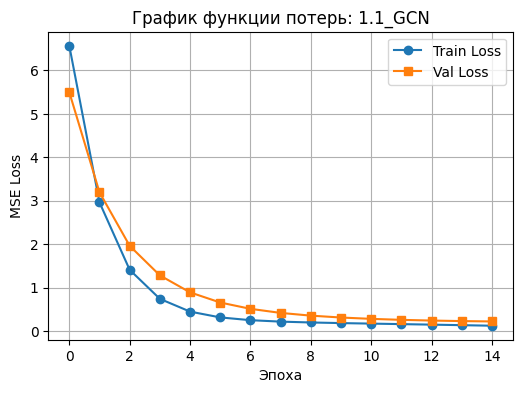

--- Обучение модели: 1.1_GAT ---
epoch 0
 L Train: 3.9218
 L Val: 2.8767
epoch 1
 L Train: 1.3246
 L Val: 1.4860
epoch 2
 L Train: 0.5875
 L Val: 0.8972
epoch 3
 L Train: 0.3315
 L Val: 0.6113
epoch 4
 L Train: 0.2259
 L Val: 0.4583
epoch 5
 L Train: 0.1745
 L Val: 0.3698
epoch 6
 L Train: 0.1449
 L Val: 0.3161
epoch 7
 L Train: 0.1252
 L Val: 0.2826
epoch 8
 L Train: 0.1104
 L Val: 0.2614
epoch 9
 L Train: 0.0986
 L Val: 0.2481
epoch 10
 L Train: 0.0891
 L Val: 0.2392
epoch 11
 L Train: 0.0814
 L Val: 0.2325
epoch 12
 L Train: 0.0752
 L Val: 0.2261
epoch 13
 L Train: 0.0700
 L Val: 0.2185
epoch 14
 L Train: 0.0653
 L Val: 0.2090


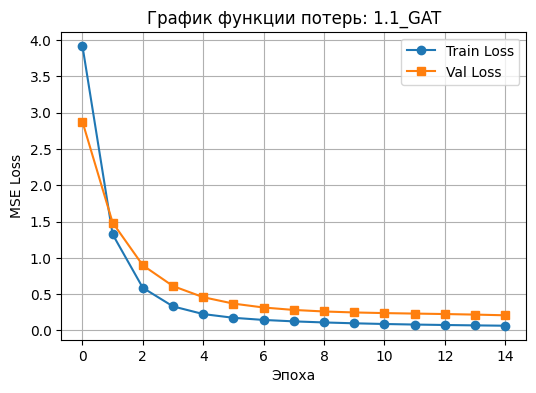

--- Обучение модели: 1.1_GraphSAGE ---
epoch 0
 L Train: 1.0882
 L Val: 0.6267
epoch 1
 L Train: 0.3949
 L Val: 0.5795
epoch 2
 L Train: 0.3809
 L Val: 0.4316
epoch 3
 L Train: 0.2731
 L Val: 0.2829
epoch 4
 L Train: 0.1592
 L Val: 0.2438
epoch 5
 L Train: 0.1271
 L Val: 0.2732
epoch 6
 L Train: 0.1489
 L Val: 0.2351
epoch 7
 L Train: 0.1248
 L Val: 0.1597
epoch 8
 L Train: 0.0772
 L Val: 0.1071
epoch 9
 L Train: 0.0487
 L Val: 0.0860
epoch 10
 L Train: 0.0428
 L Val: 0.0808
epoch 11
 L Train: 0.0461
 L Val: 0.0783
epoch 12
 L Train: 0.0484
 L Val: 0.0729
epoch 13
 L Train: 0.0462
 L Val: 0.0648
epoch 14
 L Train: 0.0401
 L Val: 0.0564


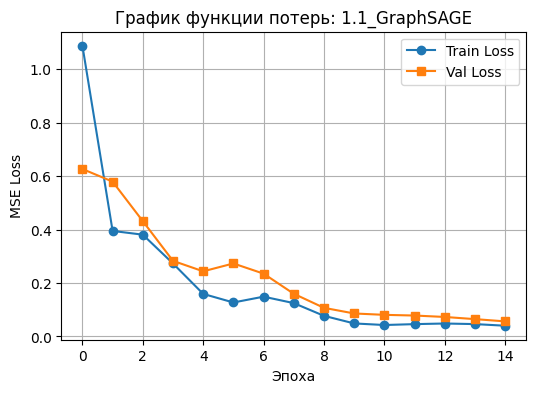

--- Обучение модели: 1.1_GIN ---
epoch 0
 L Train: 11.6216
 L Val: 0.1003
epoch 1
 L Train: 0.5450
 L Val: 0.0756
epoch 2
 L Train: 0.2392
 L Val: 0.0605
epoch 3
 L Train: 0.1327
 L Val: 0.0510
epoch 4
 L Train: 0.0845
 L Val: 0.0454
epoch 5
 L Train: 0.0604
 L Val: 0.0414
epoch 6
 L Train: 0.0469
 L Val: 0.0380
epoch 7
 L Train: 0.0390
 L Val: 0.0348
epoch 8
 L Train: 0.0336
 L Val: 0.0315
epoch 9
 L Train: 0.0294
 L Val: 0.0282
epoch 10
 L Train: 0.0258
 L Val: 0.0249
epoch 11
 L Train: 0.0226
 L Val: 0.0217
epoch 12
 L Train: 0.0197
 L Val: 0.0185
epoch 13
 L Train: 0.0173
 L Val: 0.0157
epoch 14
 L Train: 0.0152
 L Val: 0.0135


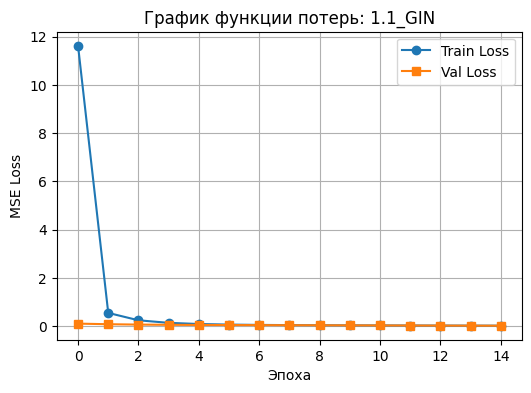

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
1.1_GCN,0.222926,0.472150,0.323620,0.160000,0.073585,0.016000,0.143333
1.1_GAT,0.208961,0.457123,0.294884,0.130000,0.063216,0.013000,0.104167
1.1_GraphSAGE,0.056419,0.237526,0.185964,0.095000,0.065361,0.010500,0.075278
1.1_GIN,0.013526,0.116302,0.096597,0.125000,0.068396,0.012500,0.096250


In [ ]:
class GCNRecommender(torch.nn.Module):
    def __init__(self, num_nodes, hidden_channels=16):
        super().__init__()
        self.emb = Embedding(num_nodes, hidden_channels)
        self.conv1 = GCNConv(hidden_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
    def forward(self, x, edge_index):
        z = self.conv2(F.relu(self.conv1(self.emb(x), edge_index)), edge_index)
        return (z[edge_index[0]] * z[edge_index[1]]).sum(dim=-1)

class GATRecommender(torch.nn.Module):
    def __init__(self, num_nodes, hidden_channels=16, heads=2):
        super().__init__()
        self.emb = Embedding(num_nodes, hidden_channels)
        self.conv1 = GATConv(hidden_channels, hidden_channels, heads=heads)
        self.conv2 = GATConv(hidden_channels * heads, hidden_channels, heads=1)
    def forward(self, x, edge_index):
        z = self.conv2(F.relu(self.conv1(self.emb(x), edge_index)), edge_index)
        return (z[edge_index[0]] * z[edge_index[1]]).sum(dim=-1)

class SAGERecommender(torch.nn.Module):
    def __init__(self, num_nodes, hidden_channels=16):
        super().__init__()
        self.emb = Embedding(num_nodes, hidden_channels)
        self.conv1 = SAGEConv(hidden_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, hidden_channels)
    def forward(self, x, edge_index):
        z = self.conv2(F.relu(self.conv1(self.emb(x), edge_index)), edge_index)
        return (z[edge_index[0]] * z[edge_index[1]]).sum(dim=-1)

class GINRecommender(torch.nn.Module):
    def __init__(self, num_nodes, hidden_channels=16):
        super().__init__()
        self.emb = Embedding(num_nodes, hidden_channels)
        self.conv1 = GINConv(Sequential(Linear(hidden_channels, hidden_channels), ReLU(), Linear(hidden_channels, hidden_channels)))
        self.conv2 = GINConv(Sequential(Linear(hidden_channels, hidden_channels), ReLU(), Linear(hidden_channels, hidden_channels)))
    def forward(self, x, edge_index):
        z = self.conv2(F.relu(self.conv1(self.emb(x), edge_index)), edge_index)
        return (z[edge_index[0]] * z[edge_index[1]]).sum(dim=-1)

m_dict = {
    '1.1_GCN': GCNRecommender(total_nodes),
    '1.1_GAT': GATRecommender(total_nodes),
    '1.1_GraphSAGE': SAGERecommender(total_nodes),
    '1.1_GIN': GINRecommender(total_nodes)
}

epochs_num = 15

for exp_name, current_model in m_dict.items():
    print(f"--- Обучение модели: {exp_name} ---")
    opt = Adam(current_model.parameters(), lr=0.01)
    crit = MSELoss()
    tr_losses = []
    vl_losses = []

    for e in range(epochs_num):
        current_model.train()
        opt.zero_grad()
        out = current_model(train_data.x, train_data.edge_index)
        t_loss = crit(out, train_data.edge_weight)
        t_loss.backward()
        opt.step()

        current_model.eval()
        with torch.no_grad():
            v_out = current_model(test_data.x, test_data.edge_index)
            v_loss = crit(v_out, test_data.edge_weight)

        tr_losses.append(t_loss.item())
        vl_losses.append(v_loss.item())
        print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

    m_res = compute_recsys_metrics(current_model, test_data, users_count, items_count)
    m_res['Experiment'] = exp_name
    global_metrics_registry.append(m_res)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(range(epochs_num), tr_losses, marker='o', label='Train Loss')
    ax.plot(range(epochs_num), vl_losses, marker='s', label='Val Loss')
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('MSE Loss')
    ax.set_title(f'График функции потерь: {exp_name}')
    ax.legend()
    ax.grid(True)
    plt.show()

render_styled_dataframe(global_metrics_registry)

## Задание 1.2: Исследование глубины. Обучение моделей с 2, 3, 4 и 5 слоями GCN. Использование `ModuleList` и Dropout.

--- Обучение модели: 1.2_GCN_Depth_2 ---
epoch 0
 L Train: 3.3894
 L Val: 2.8291
epoch 1
 L Train: 1.7926
 L Val: 1.7166
epoch 2
 L Train: 1.0144
 L Val: 1.0975
epoch 3
 L Train: 0.6524
 L Val: 0.7403
epoch 4
 L Train: 0.4521
 L Val: 0.5276
epoch 5
 L Train: 0.3504
 L Val: 0.3971
epoch 6
 L Train: 0.2858
 L Val: 0.3148
epoch 7
 L Train: 0.2477
 L Val: 0.2613
epoch 8
 L Train: 0.2218
 L Val: 0.2254
epoch 9
 L Train: 0.2005
 L Val: 0.2003
epoch 10
 L Train: 0.1829
 L Val: 0.1819
epoch 11
 L Train: 0.1681
 L Val: 0.1679
epoch 12
 L Train: 0.1516
 L Val: 0.1568
epoch 13
 L Train: 0.1352
 L Val: 0.1481
epoch 14
 L Train: 0.1201
 L Val: 0.1416


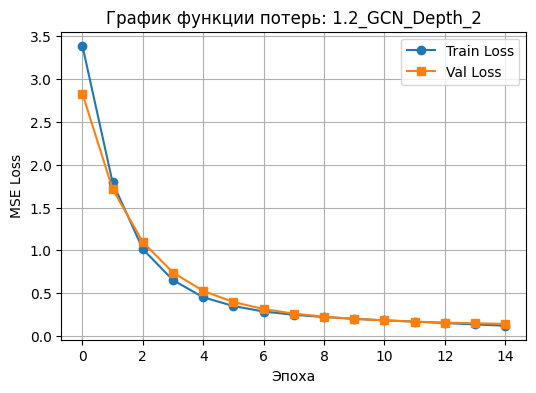

--- Обучение модели: 1.2_GCN_Depth_3 ---
epoch 0
 L Train: 0.4605
 L Val: 0.2207
epoch 1
 L Train: 0.2258
 L Val: 0.1850
epoch 2
 L Train: 0.2016
 L Val: 0.1772
epoch 3
 L Train: 0.1904
 L Val: 0.1682
epoch 4
 L Train: 0.1759
 L Val: 0.1529
epoch 5
 L Train: 0.1520
 L Val: 0.1324
epoch 6
 L Train: 0.1188
 L Val: 0.1115
epoch 7
 L Train: 0.0988
 L Val: 0.0970
epoch 8
 L Train: 0.0927
 L Val: 0.0888
epoch 9
 L Train: 0.0904
 L Val: 0.0805
epoch 10
 L Train: 0.0868
 L Val: 0.0711
epoch 11
 L Train: 0.0754
 L Val: 0.0652
epoch 12
 L Train: 0.0581
 L Val: 0.0642
epoch 13
 L Train: 0.0500
 L Val: 0.0658
epoch 14
 L Train: 0.0455
 L Val: 0.0666


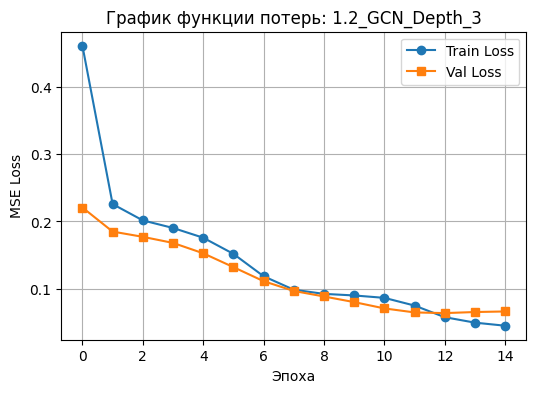

--- Обучение модели: 1.2_GCN_Depth_4 ---
epoch 0
 L Train: 0.3300
 L Val: 0.1894
epoch 1
 L Train: 0.1991
 L Val: 0.1975
epoch 2
 L Train: 0.2074
 L Val: 0.1917
epoch 3
 L Train: 0.1945
 L Val: 0.1672
epoch 4
 L Train: 0.1620
 L Val: 0.1255
epoch 5
 L Train: 0.1113
 L Val: 0.0798
epoch 6
 L Train: 0.0688
 L Val: 0.0648
epoch 7
 L Train: 0.1019
 L Val: 0.0595
epoch 8
 L Train: 0.1019
 L Val: 0.0516
epoch 9
 L Train: 0.0646
 L Val: 0.0593
epoch 10
 L Train: 0.0478
 L Val: 0.0737
epoch 11
 L Train: 0.0523
 L Val: 0.0832
epoch 12
 L Train: 0.0582
 L Val: 0.0838
epoch 13
 L Train: 0.0558
 L Val: 0.0764
epoch 14
 L Train: 0.0499
 L Val: 0.0633


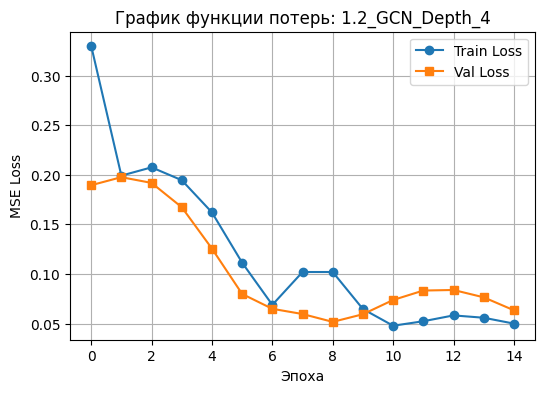

--- Обучение модели: 1.2_GCN_Depth_5 ---
epoch 0
 L Train: 0.2538
 L Val: 0.1455
epoch 1
 L Train: 0.1675
 L Val: 0.0950
epoch 2
 L Train: 0.1329
 L Val: 0.0855
epoch 3
 L Train: 0.0880
 L Val: 0.0817
epoch 4
 L Train: 0.0717
 L Val: 0.0589
epoch 5
 L Train: 0.0509
 L Val: 0.0339
epoch 6
 L Train: 0.0517
 L Val: 0.0313
epoch 7
 L Train: 0.0405
 L Val: 0.0376
epoch 8
 L Train: 0.0336
 L Val: 0.0419
epoch 9
 L Train: 0.0316
 L Val: 0.0375
epoch 10
 L Train: 0.0292
 L Val: 0.0279
epoch 11
 L Train: 0.0275
 L Val: 0.0233
epoch 12
 L Train: 0.0257
 L Val: 0.0241
epoch 13
 L Train: 0.0233
 L Val: 0.0268
epoch 14
 L Train: 0.0220
 L Val: 0.0274


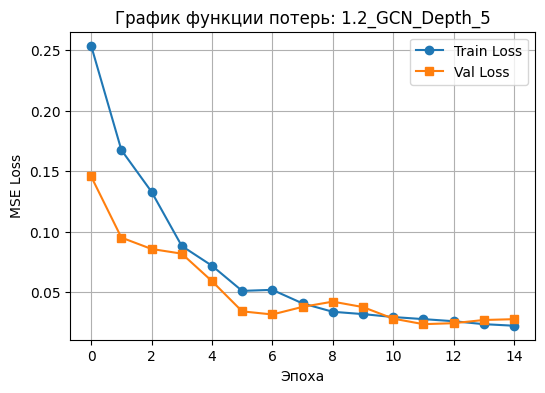

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
1.1_GCN,0.222926,0.472150,0.323620,0.160000,0.073585,0.016000,0.143333
1.1_GAT,0.208961,0.457123,0.294884,0.130000,0.063216,0.013000,0.104167
1.1_GraphSAGE,0.056419,0.237526,0.185964,0.095000,0.065361,0.010500,0.075278
1.1_GIN,0.013526,0.116302,0.096597,0.125000,0.068396,0.012500,0.096250
1.2_GCN_Depth_2,0.141625,0.376331,0.283228,0.135000,0.065225,0.016000,0.114195
1.2_GCN_Depth_3,0.066634,0.258136,0.227105,0.120000,0.052018,0.012000,0.094583
1.2_GCN_Depth_4,0.063339,0.251673,0.229018,0.140000,0.064545,0.015000,0.088261
1.2_GCN_Depth_5,0.027427,0.165610,0.146460,0.110000,0.047466,0.011000,0.083750


In [ ]:
class DeepGCNRecommender(torch.nn.Module):
    def __init__(self, num_nodes, hidden_channels=16, num_layers=2, dropout_rate=0.2):
        super().__init__()
        self.emb = Embedding(num_nodes, hidden_channels)
        self.layers = ModuleList()
        self.dropouts = ModuleList()
        self.layers.append(GCNConv(hidden_channels, hidden_channels))
        for _ in range(num_layers - 2):
            self.layers.append(GCNConv(hidden_channels, hidden_channels))
        self.layers.append(GCNConv(hidden_channels, hidden_channels))
        for _ in range(num_layers - 1):
            self.dropouts.append(Dropout(dropout_rate))

    def forward(self, x, edge_index):
        z = self.emb(x)
        for i in range(len(self.layers) - 1):
            z = self.dropouts[i](F.relu(self.layers[i](z, edge_index)))
        z = self.layers[-1](z, edge_index)
        return (z[edge_index[0]] * z[edge_index[1]]).sum(dim=-1)

depths_list = [2, 3, 4, 5]
epochs_num = 15

for d in depths_list:
    exp_name = f'1.2_GCN_Depth_{d}'
    print(f"--- Обучение модели: {exp_name} ---")
    model_deep = DeepGCNRecommender(total_nodes, num_layers=d)
    opt = Adam(model_deep.parameters(), lr=0.01)
    crit = MSELoss()
    tr_losses = []
    vl_losses = []

    for e in range(epochs_num):
        model_deep.train()
        opt.zero_grad()
        out = model_deep(train_data.x, train_data.edge_index)
        t_loss = crit(out, train_data.edge_weight)
        t_loss.backward()
        opt.step()

        model_deep.eval()
        with torch.no_grad():
            v_out = model_deep(test_data.x, test_data.edge_index)
            v_loss = crit(v_out, test_data.edge_weight)

        tr_losses.append(t_loss.item())
        vl_losses.append(v_loss.item())
        print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

    m_res = compute_recsys_metrics(model_deep, test_data, users_count, items_count)
    m_res['Experiment'] = exp_name
    global_metrics_registry.append(m_res)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(range(epochs_num), tr_losses, marker='o', label='Train Loss')
    ax.plot(range(epochs_num), vl_losses, marker='s', label='Val Loss')
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('MSE Loss')
    ax.set_title(f'График функции потерь: {exp_name}')
    ax.legend()
    ax.grid(True)
    plt.show()

render_styled_dataframe(global_metrics_registry)

## Задание 1.3: Контентные признаки. Добавление жанров и года выпуска фильма в признаки узлов.

--- Обучение модели: 1.3_GCN_Content_Features ---
epoch 0
 L Train: 7.7886
 L Val: 5.7464
epoch 1
 L Train: 2.9603
 L Val: 3.0628
epoch 2
 L Train: 1.2524
 L Val: 1.8129
epoch 3
 L Train: 0.6338
 L Val: 1.1862
epoch 4
 L Train: 0.3926
 L Val: 0.8482
epoch 5
 L Train: 0.2866
 L Val: 0.6511
epoch 6
 L Train: 0.2308
 L Val: 0.5289
epoch 7
 L Train: 0.1952
 L Val: 0.4482
epoch 8
 L Train: 0.1687
 L Val: 0.3923
epoch 9
 L Train: 0.1473
 L Val: 0.3524
epoch 10
 L Train: 0.1294
 L Val: 0.3228
epoch 11
 L Train: 0.1145
 L Val: 0.3004
epoch 12
 L Train: 0.1022
 L Val: 0.2825
epoch 13
 L Train: 0.0923
 L Val: 0.2676
epoch 14
 L Train: 0.0843
 L Val: 0.2545


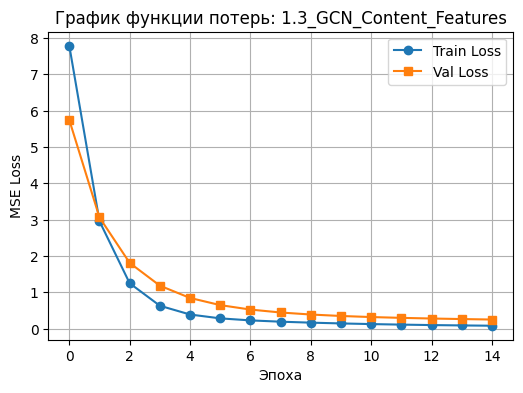

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
1.1_GCN,0.222926,0.472150,0.323620,0.160000,0.073585,0.016000,0.143333
1.1_GAT,0.208961,0.457123,0.294884,0.130000,0.063216,0.013000,0.104167
1.1_GraphSAGE,0.056419,0.237526,0.185964,0.095000,0.065361,0.010500,0.075278
1.1_GIN,0.013526,0.116302,0.096597,0.125000,0.068396,0.012500,0.096250
1.2_GCN_Depth_2,0.141625,0.376331,0.283228,0.135000,0.065225,0.016000,0.114195
1.2_GCN_Depth_3,0.066634,0.258136,0.227105,0.120000,0.052018,0.012000,0.094583
1.2_GCN_Depth_4,0.063339,0.251673,0.229018,0.140000,0.064545,0.015000,0.088261
1.2_GCN_Depth_5,0.027427,0.165610,0.146460,0.110000,0.047466,0.011000,0.083750
1.3_GCN_Content_Features,0.254497,0.504477,0.319392,0.090000,0.046328,0.009000,0.084167


In [ ]:
m_df = pd.read_csv(f'{extract_dir}/movies.csv', names=['item_id', 'title', 'genres'], header=0)
m_df = m_df[m_df['item_id'].isin(unique_items)].copy()

genre_categories = ['unknown', 'Action', 'Adventure', 'Animation', 'Childrens', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
for cat in genre_categories:
    m_df[cat] = m_df['genres'].apply(lambda x: 1 if pd.notna(x) and cat.replace('Childrens', 'Children') in x else 0)

m_df['ext_year'] = m_df['title'].str.extract(r'\((\d{4})\)').astype(float)
m_df['ext_year'] = m_df['ext_year'].fillna(m_df['ext_year'].median())
min_y = m_df['ext_year'].min(); max_y = m_df['ext_year'].max()
m_df['norm_year'] = (m_df['ext_year'] - min_y) / (max_y - min_y + 1e-6)

m_df['mapped_id'] = m_df['item_id'].map(item_map)
m_df = m_df.sort_values('mapped_id')

genres_tensor = torch.tensor(m_df[genre_categories].values, dtype=torch.float32)
year_tensor = torch.tensor(m_df['norm_year'].values, dtype=torch.float32).unsqueeze(1)
item_content = torch.cat([year_tensor, genres_tensor], dim=1)

user_padding = torch.zeros((users_count, item_content.shape[1]), dtype=torch.float32)
full_content_x = torch.cat([user_padding, item_content], dim=0)

train_data_enriched = Data(x=node_features, content_x=full_content_x, edge_index=edge_index[:, train_mask], edge_weight=edge_weight[train_mask])
test_data_enriched = Data(x=node_features, content_x=full_content_x, edge_index=edge_index[:, test_mask], edge_weight=edge_weight[test_mask])

class ContentGCNRecommender(torch.nn.Module):
    def __init__(self, num_nodes, content_dim, hidden_channels=16):
        super().__init__()
        self.emb = Embedding(num_nodes, hidden_channels)
        self.content_proj = Linear(content_dim, hidden_channels)
        self.conv1 = GCNConv(hidden_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
    def forward(self, x, content_x, edge_index):
        # Если это пользователь, content_proj зануляется из-за user_padding, остается только emb(x)
        z = self.emb(x) + F.relu(self.content_proj(content_x))
        z = self.conv2(F.relu(self.conv1(z, edge_index)), edge_index)
        return (z[edge_index[0]] * z[edge_index[1]]).sum(dim=-1)

exp_name = '1.3_GCN_Content_Features'
print(f"--- Обучение модели: {exp_name} ---")
model_enriched = ContentGCNRecommender(total_nodes, content_dim=20)
opt = Adam(model_enriched.parameters(), lr=0.01)
crit = MSELoss()
tr_losses = []
vl_losses = []
epochs_num = 15

for e in range(epochs_num):
    model_enriched.train()
    opt.zero_grad()
    out = model_enriched(train_data_enriched.x, train_data_enriched.content_x, train_data_enriched.edge_index)
    t_loss = crit(out, train_data_enriched.edge_weight)
    t_loss.backward()
    opt.step()

    model_enriched.eval()
    with torch.no_grad():
        v_out = model_enriched(test_data_enriched.x, test_data_enriched.content_x, test_data_enriched.edge_index)
        v_loss = crit(v_out, test_data_enriched.edge_weight)

    tr_losses.append(t_loss.item())
    vl_losses.append(v_loss.item())
    print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

def compute_recsys_metrics_content(model, data, u_count, i_count, sample_size=200):
    model.eval()
    with torch.no_grad():
        preds = model(data.x, data.content_x, data.edge_index).cpu().numpy()
        true_vals = data.edge_weight.cpu().numpy()
        mse = mean_squared_error(true_vals, preds)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(true_vals, preds)
        users = data.edge_index[0].cpu().numpy()
        items = data.edge_index[1].cpu().numpy()
        df_eval = pd.DataFrame({'u': users, 'i': items, 'p': preds})
        df_eval = df_eval[df_eval['u'] < u_count]
        hits = []; mrrs = []; precs = []; recs = []
        eval_users = df_eval['u'].unique()
        if len(eval_users) > sample_size:
            eval_users = np.random.choice(eval_users, sample_size, replace=False)
        for u in eval_users:
            u_group = df_eval[df_eval['u'] == u]
            pos_items = u_group['i'].values
            if len(pos_items) == 0: continue
            neg_items = np.random.randint(u_count, u_count + i_count, 100)
            test_u = np.full(100 + len(pos_items), u)
            test_i = np.concatenate([pos_items, neg_items])
            test_edges = torch.tensor([test_u, test_i], dtype=torch.long).to(data.x.device)
            p_scores = model(data.x, data.content_x, test_edges).cpu().numpy()
            all_labels = np.concatenate([np.ones(len(pos_items)), np.zeros(len(neg_items))])
            sort_idx = np.argsort(p_scores)[::-1]
            sorted_labels = all_labels[sort_idx]
            top10 = sorted_labels[:10]
            hits.append(1 if np.sum(top10) > 0 else 0)
            first_pos = np.where(sorted_labels == 1)[0]
            mrrs.append(1.0 / (first_pos[0] + 1) if len(first_pos) > 0 else 0.0)
            precs.append(np.sum(top10) / 10.0)
            recs.append(np.sum(top10) / len(pos_items))
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'Hits@10': np.mean(hits), 'MRR': np.mean(mrrs), 'Precision@10': np.mean(precs), 'Recall@10': np.mean(recs)}

m_res = compute_recsys_metrics_content(model_enriched, test_data_enriched, users_count, items_count)
m_res['Experiment'] = exp_name
global_metrics_registry.append(m_res)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(epochs_num), tr_losses, marker='o', label='Train Loss')
ax.plot(range(epochs_num), vl_losses, marker='s', label='Val Loss')
ax.set_xlabel('Эпоха')
ax.set_ylabel('MSE Loss')
ax.set_title(f'График функции потерь: {exp_name}')
ax.legend()
ax.grid(True)
plt.show()

render_styled_dataframe(global_metrics_registry)

## Задание 1.4: Анализ холодного старта. Удаление 30% пользователей из обучения и реализация стратегий рекомендации для новичков.

In [ ]:
drop_ratio = 0.3
unique_train_users = torch.unique(edge_index[0][edge_index[0] < users_count])
drop_count = int(len(unique_train_users) * drop_ratio)
shuffled_users = unique_train_users[torch.randperm(len(unique_train_users))]
cold_user_indices = shuffled_users[:drop_count]

keep_mask = ~torch.isin(edge_index[0], cold_user_indices)
cold_train_edge_index = edge_index[:, keep_mask]
cold_train_edge_weight = edge_weight[keep_mask]

item_popularity = torch.zeros(items_count, dtype=torch.float32)
valid_item_mask = cold_train_edge_index[0] < users_count
target_items = cold_train_edge_index[1][valid_item_mask] - users_count
target_weights = cold_train_edge_weight[valid_item_mask]

for i in range(len(target_items)):
    item_popularity[target_items[i]] += target_weights[i]

exp_name = '1.4_Heuristic_Cold_Start'
print(f"--- Оценка подхода: {exp_name} ---")

hits = []; mrrs = []; precs = []; recs = []
cold_users_cpu = cold_user_indices.cpu().numpy()
eval_users = np.random.choice(cold_users_cpu, min(200, len(cold_users_cpu)), replace=False)

df_all_edges = pd.DataFrame({'u': edge_index[0].cpu().numpy(), 'i': edge_index[1].cpu().numpy()})
df_all_edges = df_all_edges[df_all_edges['u'] < users_count]

for u in eval_users:
    pos_items = df_all_edges[df_all_edges['u'] == u]['i'].values
    if len(pos_items) == 0: continue

    neg_items = np.random.randint(users_count, users_count + items_count, 100)
    test_i = np.concatenate([pos_items, neg_items])

    p_scores = np.array([item_popularity[i - users_count].item() if i >= users_count else 0 for i in test_i])
    all_labels = np.concatenate([np.ones(len(pos_items)), np.zeros(len(neg_items))])

    sort_idx = np.argsort(p_scores)[::-1]
    sorted_labels = all_labels[sort_idx]
    top10 = sorted_labels[:10]

    hits.append(1 if np.sum(top10) > 0 else 0)
    first_pos = np.where(sorted_labels == 1)[0]
    mrrs.append(1.0 / (first_pos[0] + 1) if len(first_pos) > 0 else 0.0)
    precs.append(np.sum(top10) / 10.0)
    recs.append(np.sum(top10) / len(pos_items))

m_res = {
    'Experiment': exp_name,
    'MSE': np.nan, 'RMSE': np.nan, 'MAE': np.nan,
    'Hits@10': np.mean(hits),
    'MRR': np.mean(mrrs),
    'Precision@10': np.mean(precs),
    'Recall@10': np.mean(recs)
}
global_metrics_registry.append(m_res)

print("ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА ЧАСТИ 1:")
render_styled_dataframe(global_metrics_registry)

--- Оценка подхода: 1.4_Heuristic_Cold_Start ---
ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА ЧАСТИ 1:


,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
1.1_GCN,0.222926,0.472150,0.323620,0.160000,0.073585,0.016000,0.143333
1.1_GAT,0.208961,0.457123,0.294884,0.130000,0.063216,0.013000,0.104167
1.1_GraphSAGE,0.056419,0.237526,0.185964,0.095000,0.065361,0.010500,0.075278
1.1_GIN,0.013526,0.116302,0.096597,0.125000,0.068396,0.012500,0.096250
1.2_GCN_Depth_2,0.141625,0.376331,0.283228,0.135000,0.065225,0.016000,0.114195
1.2_GCN_Depth_3,0.066634,0.258136,0.227105,0.120000,0.052018,0.012000,0.094583
1.2_GCN_Depth_4,0.063339,0.251673,0.229018,0.140000,0.064545,0.015000,0.088261
1.2_GCN_Depth_5,0.027427,0.165610,0.146460,0.110000,0.047466,0.011000,0.083750
1.3_GCN_Content_Features,0.254497,0.504477,0.319392,0.090000,0.046328,0.009000,0.084167


# 7. Применение LightGCN (RecBole)
* Установка библиотеки `RecBole`.
* Подготовка данных MovieLens-1M в формате `.inter`.
* Настройка конфигурации: `embedding_size`, `n_layers`, `reg_weight`, `learning_rate`.
* Загрузка данных и разделение через `data_preparation`.
* Обучение модели `LightGCN` через `Trainer`.
* Оценка производительности (NDCG, Recall).
* Визуализация эмбеддингов через t-SNE для пользователей и товаров.

# Задания к части 2 (Самостоятельно)


In [ ]:
import pandas as pd; import torch; import numpy as np; import matplotlib.pyplot as plt; import torch.nn.functional as F
from torch_geometric.nn import LightGCN; from sklearn.model_selection import train_test_split

f_df = pd.read_csv('fashion_products.csv')
u_map = {uid: i for i, uid in enumerate(f_df['User ID'].unique())}
i_map = {iid: i for i, iid in enumerate(f_df['Product ID'].unique())}
u_count = len(u_map)
i_count = len(i_map)

u_t = torch.tensor([u_map[u] for u in f_df['User ID']], dtype=torch.long)
i_t = torch.tensor([i_map[i] + u_count for i in f_df['Product ID']], dtype=torch.long)
f_edges = torch.stack([u_t, i_t], dim=0)

tr_idx, vl_idx = train_test_split(range(f_edges.size(1)), test_size=0.2, random_state=42)
f_train_edges = f_edges[:, tr_idx]
f_val_edges = f_edges[:, vl_idx]

part2_metrics_registry = []

def get_bpr_loss(model, edges, train_edges, num_u, num_i):
    u_idx = edges[0]
    pos_i = edges[1]
    neg_i = torch.randint(num_u, num_u + num_i, (u_idx.size(0),), dtype=torch.long, device=edges.device)
    embs = model.get_embedding(train_edges)
    pos_scores = (embs[u_idx] * embs[pos_i]).sum(dim=1)
    neg_scores = (embs[u_idx] * embs[neg_i]).sum(dim=1)
    unique_nodes = torch.unique(torch.cat([u_idx, pos_i, neg_i]))
    return model.recommendation_loss(pos_scores, neg_scores, node_id=unique_nodes)

def compute_implicit_metrics(model, train_edges, test_edges, num_u, num_i, sample_size=200):
    model.eval()
    with torch.no_grad():
        embs = model.get_embedding(train_edges).cpu().numpy()
        test_u = test_edges[0].cpu().numpy()
        test_i = test_edges[1].cpu().numpy()
        df_eval = pd.DataFrame({'u': test_u, 'i': test_i})

        hits = []; mrrs = []; precs = []; recs = []
        eval_users = df_eval['u'].unique()
        if len(eval_users) > sample_size:
            eval_users = np.random.choice(eval_users, sample_size, replace=False)

        for u in eval_users:
            pos_items = df_eval[df_eval['u'] == u]['i'].values
            if len(pos_items) == 0: continue

            neg_items = np.random.randint(num_u, num_u + num_i, 100)
            test_items = np.concatenate([pos_items, neg_items])

            u_emb = embs[u]
            i_embs = embs[test_items]
            scores = np.dot(i_embs, u_emb)

            labels = np.concatenate([np.ones(len(pos_items)), np.zeros(len(neg_items))])
            sort_idx = np.argsort(scores)[::-1]
            sorted_labels = labels[sort_idx]
            top10 = sorted_labels[:10]

            hits.append(1 if np.sum(top10) > 0 else 0)
            first_pos = np.where(sorted_labels == 1)[0]
            mrrs.append(1.0 / (first_pos[0] + 1) if len(first_pos) > 0 else 0.0)
            precs.append(np.sum(top10) / 10.0)
            recs.append(np.sum(top10) / len(pos_items))

    return {'MSE': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Hits@10': np.mean(hits), 'MRR': np.mean(mrrs), 'Precision@10': np.mean(precs), 'Recall@10': np.mean(recs)}

def render_implicit_dataframe(registry_list):
    df_m = pd.DataFrame(registry_list)
    df_m.set_index('Experiment', inplace=True)
    higher_better = ['Hits@10', 'MRR', 'Precision@10', 'Recall@10']
    styler = df_m.style
    for col in higher_better:
        if col in df_m.columns:
            styler = styler.background_gradient(subset=[col], cmap='RdYlGn')
    display(styler)

## Задание 2.1: Оптимизация гиперпараметров (размер эмбеддингов, слои, регуляризация).

--- Обучение модели: 2.1_LightGCN_L2_E32 ---
epoch 0
 L Train: 0.6931
 L Val: 0.6932
epoch 1
 L Train: 0.6925
 L Val: 0.6931
epoch 2
 L Train: 0.6918
 L Val: 0.6931
epoch 3
 L Train: 0.6910
 L Val: 0.6930
epoch 4
 L Train: 0.6901
 L Val: 0.6931
epoch 5
 L Train: 0.6890
 L Val: 0.6930
epoch 6
 L Train: 0.6877
 L Val: 0.6931
epoch 7
 L Train: 0.6862
 L Val: 0.6932
epoch 8
 L Train: 0.6845
 L Val: 0.6929
epoch 9
 L Train: 0.6825
 L Val: 0.6931
epoch 10
 L Train: 0.6804
 L Val: 0.6929
epoch 11
 L Train: 0.6781
 L Val: 0.6930
epoch 12
 L Train: 0.6754
 L Val: 0.6933
epoch 13
 L Train: 0.6728
 L Val: 0.6931
epoch 14
 L Train: 0.6696
 L Val: 0.6928


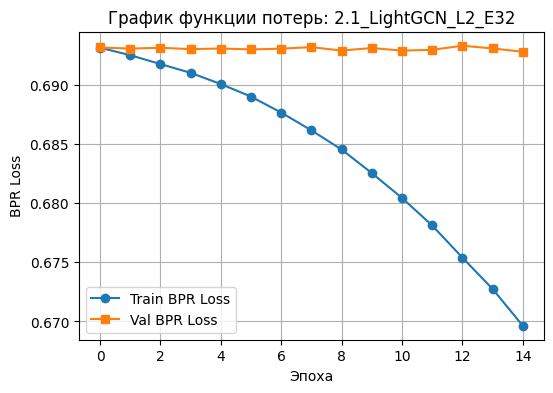

--- Обучение модели: 2.1_LightGCN_L2_E64 ---
epoch 0
 L Train: 0.6931
 L Val: 0.6932
epoch 1
 L Train: 0.6918
 L Val: 0.6932
epoch 2
 L Train: 0.6905
 L Val: 0.6933
epoch 3
 L Train: 0.6889
 L Val: 0.6934
epoch 4
 L Train: 0.6871
 L Val: 0.6933
epoch 5
 L Train: 0.6848
 L Val: 0.6933
epoch 6
 L Train: 0.6823
 L Val: 0.6932
epoch 7
 L Train: 0.6793
 L Val: 0.6931
epoch 8
 L Train: 0.6758
 L Val: 0.6933
epoch 9
 L Train: 0.6723
 L Val: 0.6933
epoch 10
 L Train: 0.6678
 L Val: 0.6935
epoch 11
 L Train: 0.6633
 L Val: 0.6936
epoch 12
 L Train: 0.6579
 L Val: 0.6936
epoch 13
 L Train: 0.6524
 L Val: 0.6937
epoch 14
 L Train: 0.6461
 L Val: 0.6953


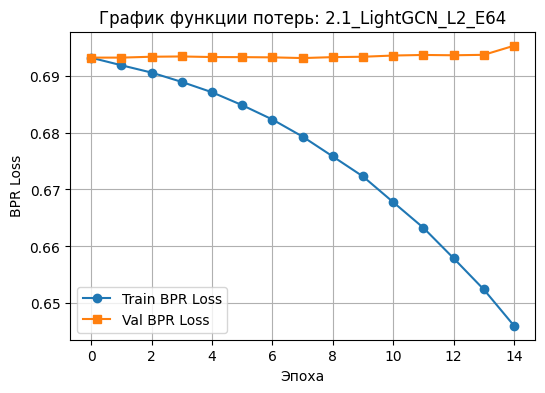

--- Обучение модели: 2.1_LightGCN_L3_E32 ---
epoch 0
 L Train: 0.6932
 L Val: 0.6932
epoch 1
 L Train: 0.6928
 L Val: 0.6932
epoch 2
 L Train: 0.6924
 L Val: 0.6932
epoch 3
 L Train: 0.6919
 L Val: 0.6931
epoch 4
 L Train: 0.6914
 L Val: 0.6932
epoch 5
 L Train: 0.6908
 L Val: 0.6931
epoch 6
 L Train: 0.6901
 L Val: 0.6933
epoch 7
 L Train: 0.6892
 L Val: 0.6933
epoch 8
 L Train: 0.6883
 L Val: 0.6933
epoch 9
 L Train: 0.6873
 L Val: 0.6933
epoch 10
 L Train: 0.6860
 L Val: 0.6934
epoch 11
 L Train: 0.6846
 L Val: 0.6934
epoch 12
 L Train: 0.6831
 L Val: 0.6935
epoch 13
 L Train: 0.6817
 L Val: 0.6933
epoch 14
 L Train: 0.6798
 L Val: 0.6933


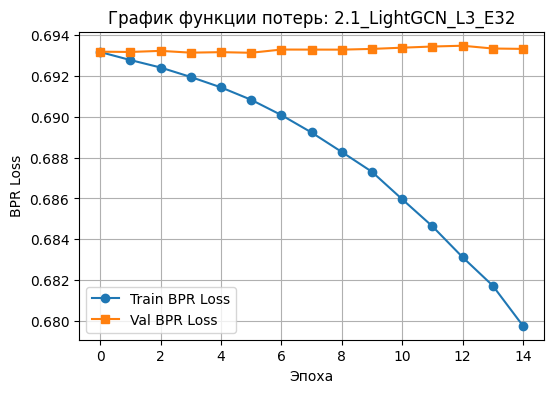

--- Обучение модели: 2.1_LightGCN_L3_E64 ---
epoch 0
 L Train: 0.6932
 L Val: 0.6931
epoch 1
 L Train: 0.6925
 L Val: 0.6931
epoch 2
 L Train: 0.6917
 L Val: 0.6932
epoch 3
 L Train: 0.6909
 L Val: 0.6931
epoch 4
 L Train: 0.6898
 L Val: 0.6932
epoch 5
 L Train: 0.6885
 L Val: 0.6932
epoch 6
 L Train: 0.6872
 L Val: 0.6932
epoch 7
 L Train: 0.6855
 L Val: 0.6935
epoch 8
 L Train: 0.6836
 L Val: 0.6932
epoch 9
 L Train: 0.6815
 L Val: 0.6934
epoch 10
 L Train: 0.6791
 L Val: 0.6933
epoch 11
 L Train: 0.6763
 L Val: 0.6928
epoch 12
 L Train: 0.6735
 L Val: 0.6930
epoch 13
 L Train: 0.6703
 L Val: 0.6929
epoch 14
 L Train: 0.6667
 L Val: 0.6928


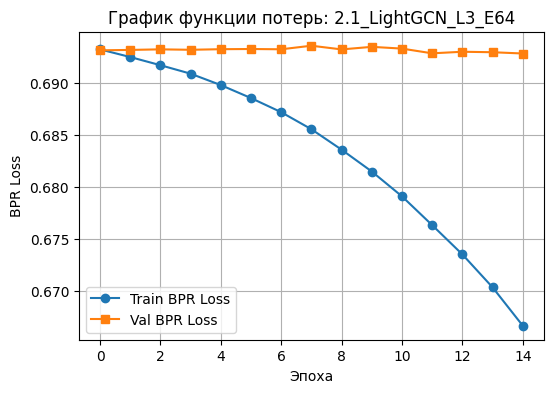

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
2.1_LightGCN_L2_E32,nan,nan,nan,0.044944,0.040133,0.004494,0.031835
2.1_LightGCN_L2_E64,nan,nan,nan,0.000000,0.033832,0.000000,0.000000
2.1_LightGCN_L3_E32,nan,nan,nan,0.022472,0.030712,0.002247,0.008427
2.1_LightGCN_L3_E64,nan,nan,nan,0.022472,0.037360,0.002247,0.022472


In [ ]:
emb_opts = [32, 64]
layer_opts = [2, 3]
epochs_num = 15

for l_count in layer_opts:
    for e_dim in emb_opts:
        exp_name = f'2.1_LightGCN_L{l_count}_E{e_dim}'
        print(f"--- Обучение модели: {exp_name} ---")

        model_lgcn = LightGCN(num_nodes=u_count + i_count, embedding_dim=e_dim, num_layers=l_count)
        opt_lgcn = torch.optim.Adam(model_lgcn.parameters(), lr=0.01)

        tr_losses = []
        vl_losses = []

        for e in range(epochs_num):
            model_lgcn.train()
            opt_lgcn.zero_grad()
            t_loss = get_bpr_loss(model_lgcn, f_train_edges, f_train_edges, u_count, i_count)
            t_loss.backward()
            opt_lgcn.step()

            model_lgcn.eval()
            with torch.no_grad():
                v_loss = get_bpr_loss(model_lgcn, f_val_edges, f_train_edges, u_count, i_count)

            tr_losses.append(t_loss.item())
            vl_losses.append(v_loss.item())
            print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

        m_res = compute_implicit_metrics(model_lgcn, f_train_edges, f_val_edges, u_count, i_count)
        m_res['Experiment'] = exp_name
        part2_metrics_registry.append(m_res)

        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(range(epochs_num), tr_losses, marker='o', label='Train BPR Loss')
        ax.plot(range(epochs_num), vl_losses, marker='s', label='Val BPR Loss')
        ax.set_xlabel('Эпоха')
        ax.set_ylabel('BPR Loss')
        ax.set_title(f'График функции потерь: {exp_name}')
        ax.legend()
        ax.grid(True)
        plt.show()

render_implicit_dataframe(part2_metrics_registry)

## Задание 2.2: Анализ разреженности (Sparsity). Искусственное удаление связей (50-95%) и замер падения качества.

--- Обучение модели: 2.2_LightGCN_Sparsity_50% ---
epoch 0
 L Train: 0.6932
 L Val: 0.6932
epoch 1
 L Train: 0.6924
 L Val: 0.6932
epoch 2
 L Train: 0.6915
 L Val: 0.6932
epoch 3
 L Train: 0.6906
 L Val: 0.6934
epoch 4
 L Train: 0.6895
 L Val: 0.6931
epoch 5
 L Train: 0.6883
 L Val: 0.6933
epoch 6
 L Train: 0.6870
 L Val: 0.6933
epoch 7
 L Train: 0.6854
 L Val: 0.6932
epoch 8
 L Train: 0.6834
 L Val: 0.6933
epoch 9
 L Train: 0.6813
 L Val: 0.6933
epoch 10
 L Train: 0.6790
 L Val: 0.6933
epoch 11
 L Train: 0.6763
 L Val: 0.6931
epoch 12
 L Train: 0.6735
 L Val: 0.6937
epoch 13
 L Train: 0.6704
 L Val: 0.6935
epoch 14
 L Train: 0.6668
 L Val: 0.6937


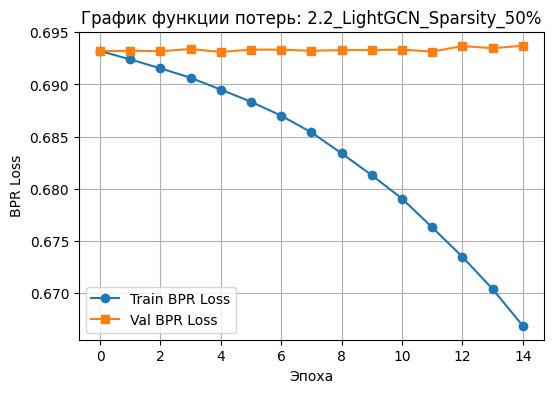

--- Обучение модели: 2.2_LightGCN_Sparsity_75% ---
epoch 0
 L Train: 0.6931
 L Val: 0.6931
epoch 1
 L Train: 0.6923
 L Val: 0.6931
epoch 2
 L Train: 0.6913
 L Val: 0.6932
epoch 3
 L Train: 0.6902
 L Val: 0.6932
epoch 4
 L Train: 0.6891
 L Val: 0.6932
epoch 5
 L Train: 0.6879
 L Val: 0.6932
epoch 6
 L Train: 0.6864
 L Val: 0.6932
epoch 7
 L Train: 0.6845
 L Val: 0.6931
epoch 8
 L Train: 0.6827
 L Val: 0.6932
epoch 9
 L Train: 0.6804
 L Val: 0.6931
epoch 10
 L Train: 0.6776
 L Val: 0.6932
epoch 11
 L Train: 0.6747
 L Val: 0.6932
epoch 12
 L Train: 0.6721
 L Val: 0.6933
epoch 13
 L Train: 0.6684
 L Val: 0.6931
epoch 14
 L Train: 0.6649
 L Val: 0.6931


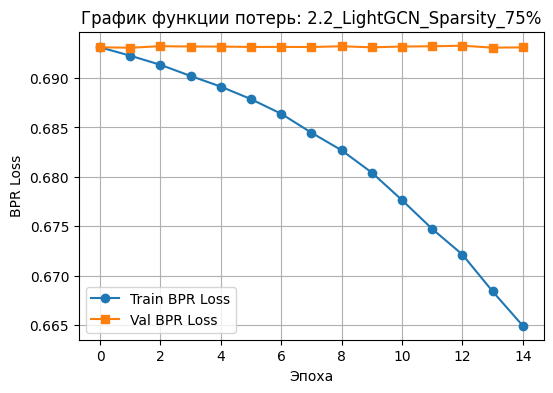

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
2.1_LightGCN_L2_E32,nan,nan,nan,0.044944,0.040133,0.004494,0.031835
2.1_LightGCN_L2_E64,nan,nan,nan,0.000000,0.033832,0.000000,0.000000
2.1_LightGCN_L3_E32,nan,nan,nan,0.022472,0.030712,0.002247,0.008427
2.1_LightGCN_L3_E64,nan,nan,nan,0.022472,0.037360,0.002247,0.022472
2.2_LightGCN_Sparsity_50%,nan,nan,nan,0.067416,0.039353,0.006742,0.036891
2.2_LightGCN_Sparsity_75%,nan,nan,nan,0.123596,0.061386,0.012360,0.072472


In [ ]:
sparsity_ratios = [0.5, 0.75]
epochs_num = 15
total_tr_edges = f_train_edges.size(1)

for s_ratio in sparsity_ratios:
    exp_name = f'2.2_LightGCN_Sparsity_{int(s_ratio*100)}%'
    print(f"--- Обучение модели: {exp_name} ---")

    retained_count = int(total_tr_edges * (1 - s_ratio))
    kept_idx = torch.randperm(total_tr_edges)[:retained_count]
    sparse_train_edges = f_train_edges[:, kept_idx]

    sparse_model = LightGCN(num_nodes=u_count + i_count, embedding_dim=32, num_layers=2)
    s_opt = torch.optim.Adam(sparse_model.parameters(), lr=0.01)

    tr_losses = []
    vl_losses = []

    for e in range(epochs_num):
        sparse_model.train()
        s_opt.zero_grad()
        t_loss = get_bpr_loss(sparse_model, sparse_train_edges, sparse_train_edges, u_count, i_count)
        t_loss.backward()
        s_opt.step()

        sparse_model.eval()
        with torch.no_grad():
            v_loss = get_bpr_loss(sparse_model, f_val_edges, sparse_train_edges, u_count, i_count)

        tr_losses.append(t_loss.item())
        vl_losses.append(v_loss.item())
        print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

    m_res = compute_implicit_metrics(sparse_model, sparse_train_edges, f_val_edges, u_count, i_count)
    m_res['Experiment'] = exp_name
    part2_metrics_registry.append(m_res)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(range(epochs_num), tr_losses, marker='o', label='Train BPR Loss')
    ax.plot(range(epochs_num), vl_losses, marker='s', label='Val BPR Loss')
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('BPR Loss')
    ax.set_title(f'График функции потерь: {exp_name}')
    ax.legend()
    ax.grid(True)
    plt.show()

render_implicit_dataframe(part2_metrics_registry)

## Задание 2.3: Борьба с Popularity Bias. Реализация пост-процессинга для дебиасинга популярных товаров.

In [ ]:
exp_name_base = '2.3_Base_Before_Debias'
exp_name_debias = '2.3_After_Popularity_Debias'
epochs_num = 15

print(f"--- Обучение модели: {exp_name_base} ---")
best_model = LightGCN(num_nodes=u_count + i_count, embedding_dim=32, num_layers=2)
best_opt = torch.optim.Adam(best_model.parameters(), lr=0.01)

tr_losses = []
vl_losses = []

for e in range(epochs_num):
    best_model.train()
    best_opt.zero_grad()
    t_loss = get_bpr_loss(best_model, f_train_edges, f_train_edges, u_count, i_count)
    t_loss.backward()
    best_opt.step()

    best_model.eval()
    with torch.no_grad():
        v_loss = get_bpr_loss(best_model, f_val_edges, f_train_edges, u_count, i_count)

    tr_losses.append(t_loss.item())
    vl_losses.append(v_loss.item())
    print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

m_res_base = compute_implicit_metrics(best_model, f_train_edges, f_val_edges, u_count, i_count)
m_res_base['Experiment'] = exp_name_base
part2_metrics_registry.append(m_res_base)

best_model.eval()
with torch.no_grad():
    embs = best_model.get_embedding(f_train_edges).cpu().numpy()
    i_counts = torch.bincount(f_train_edges[1] - u_count, minlength=i_count).float().cpu().numpy()
    pop_penalty = np.log1p(i_counts)
    alpha_penalty = 0.1

    test_u = f_val_edges[0].cpu().numpy()
    test_i = f_val_edges[1].cpu().numpy()
    df_eval = pd.DataFrame({'u': test_u, 'i': test_i})

    hits = []; mrrs = []; precs = []; recs = []
    eval_users = df_eval['u'].unique()
    eval_users = np.random.choice(eval_users, min(200, len(eval_users)), replace=False)

    for u in eval_users:
        pos_items = df_eval[df_eval['u'] == u]['i'].values
        if len(pos_items) == 0: continue

        neg_items = np.random.randint(u_count, u_count + i_count, 100)
        test_items = np.concatenate([pos_items, neg_items])

        u_emb = embs[u]
        i_embs = embs[test_items]
        raw_scores = np.dot(i_embs, u_emb)

        current_penalties = np.array([pop_penalty[i - u_count] if i >= u_count else 0 for i in test_items])
        debiased_scores = raw_scores - alpha_penalty * current_penalties

        labels = np.concatenate([np.ones(len(pos_items)), np.zeros(len(neg_items))])
        sort_idx = np.argsort(debiased_scores)[::-1]
        sorted_labels = labels[sort_idx]
        top10 = sorted_labels[:10]

        hits.append(1 if np.sum(top10) > 0 else 0)
        first_pos = np.where(sorted_labels == 1)[0]
        mrrs.append(1.0 / (first_pos[0] + 1) if len(first_pos) > 0 else 0.0)
        precs.append(np.sum(top10) / 10.0)
        recs.append(np.sum(top10) / len(pos_items))

m_res_debias = {'MSE': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Hits@10': np.mean(hits), 'MRR': np.mean(mrrs), 'Precision@10': np.mean(precs), 'Recall@10': np.mean(recs)}
m_res_debias['Experiment'] = exp_name_debias
part2_metrics_registry.append(m_res_debias)

render_implicit_dataframe(part2_metrics_registry)

--- Обучение модели: 2.3_Base_Before_Debias ---
epoch 0
 L Train: 0.6932
 L Val: 0.6932
epoch 1
 L Train: 0.6925
 L Val: 0.6931
epoch 2
 L Train: 0.6919
 L Val: 0.6932
epoch 3
 L Train: 0.6911
 L Val: 0.6932
epoch 4
 L Train: 0.6901
 L Val: 0.6932
epoch 5
 L Train: 0.6891
 L Val: 0.6931
epoch 6
 L Train: 0.6879
 L Val: 0.6932
epoch 7
 L Train: 0.6863
 L Val: 0.6935
epoch 8
 L Train: 0.6847
 L Val: 0.6933
epoch 9
 L Train: 0.6828
 L Val: 0.6929
epoch 10
 L Train: 0.6807
 L Val: 0.6933
epoch 11
 L Train: 0.6786
 L Val: 0.6932
epoch 12
 L Train: 0.6756
 L Val: 0.6932
epoch 13
 L Train: 0.6729
 L Val: 0.6936
epoch 14
 L Train: 0.6695
 L Val: 0.6939


,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
2.1_LightGCN_L2_E32,nan,nan,nan,0.044944,0.040133,0.004494,0.031835
2.1_LightGCN_L2_E64,nan,nan,nan,0.000000,0.033832,0.000000,0.000000
2.1_LightGCN_L3_E32,nan,nan,nan,0.022472,0.030712,0.002247,0.008427
2.1_LightGCN_L3_E64,nan,nan,nan,0.022472,0.037360,0.002247,0.022472
2.2_LightGCN_Sparsity_50%,nan,nan,nan,0.067416,0.039353,0.006742,0.036891
2.2_LightGCN_Sparsity_75%,nan,nan,nan,0.123596,0.061386,0.012360,0.072472
2.3_Base_Before_Debias,nan,nan,nan,0.033708,0.033438,0.004494,0.024345
2.3_After_Popularity_Debias,nan,nan,nan,0.595506,0.233621,0.091011,0.405056


## Задание 2.4: Эксперименты с функциями потерь (BPR, MSE, Contrastive Loss, InfoNCE).

--- Обучение модели: 2.4_LightGCN_Contrastive_Loss ---
epoch 0
 L Train: 1.0000
 L Val: 1.0001
epoch 1
 L Train: 0.9986
 L Val: 1.0002
epoch 2
 L Train: 0.9972
 L Val: 1.0003
epoch 3
 L Train: 0.9957
 L Val: 1.0001
epoch 4
 L Train: 0.9937
 L Val: 0.9998
epoch 5
 L Train: 0.9914
 L Val: 1.0002
epoch 6
 L Train: 0.9889
 L Val: 1.0000
epoch 7
 L Train: 0.9859
 L Val: 0.9998
epoch 8
 L Train: 0.9826
 L Val: 1.0001
epoch 9
 L Train: 0.9782
 L Val: 1.0005
epoch 10
 L Train: 0.9739
 L Val: 1.0002
epoch 11
 L Train: 0.9695
 L Val: 0.9998
epoch 12
 L Train: 0.9636
 L Val: 1.0006
epoch 13
 L Train: 0.9575
 L Val: 1.0006
epoch 14
 L Train: 0.9510
 L Val: 1.0013


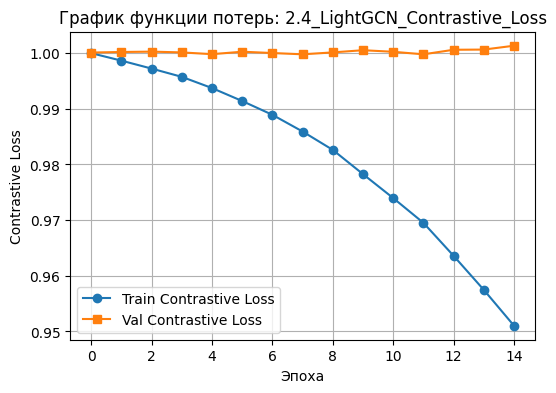

ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА ЧАСТИ 2:


,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
2.1_LightGCN_L2_E32,nan,nan,nan,0.044944,0.040133,0.004494,0.031835
2.1_LightGCN_L2_E64,nan,nan,nan,0.000000,0.033832,0.000000,0.000000
2.1_LightGCN_L3_E32,nan,nan,nan,0.022472,0.030712,0.002247,0.008427
2.1_LightGCN_L3_E64,nan,nan,nan,0.022472,0.037360,0.002247,0.022472
2.2_LightGCN_Sparsity_50%,nan,nan,nan,0.067416,0.039353,0.006742,0.036891
2.2_LightGCN_Sparsity_75%,nan,nan,nan,0.123596,0.061386,0.012360,0.072472
2.3_Base_Before_Debias,nan,nan,nan,0.033708,0.033438,0.004494,0.024345
2.3_After_Popularity_Debias,nan,nan,nan,0.595506,0.233621,0.091011,0.405056
2.4_LightGCN_Contrastive_Loss,nan,nan,nan,0.022472,0.033851,0.002247,0.008427


In [ ]:
exp_name = '2.4_LightGCN_Contrastive_Loss'
print(f"--- Обучение модели: {exp_name} ---")

c_model = LightGCN(num_nodes=u_count + i_count, embedding_dim=32, num_layers=2)
c_opt = torch.optim.Adam(c_model.parameters(), lr=0.01)
margin_val = 1.0
epochs_num = 15

tr_losses = []
vl_losses = []

for e in range(epochs_num):
    c_model.train()
    c_opt.zero_grad()

    c_users = f_train_edges[0]
    c_pos = f_train_edges[1]
    c_neg = torch.randint(u_count, u_count + i_count, (c_users.size(0),), dtype=torch.long, device=f_train_edges.device)

    embs_tr = c_model.get_embedding(f_train_edges)
    pos_sc = (embs_tr[c_users] * embs_tr[c_pos]).sum(dim=1)
    neg_sc = (embs_tr[c_users] * embs_tr[c_neg]).sum(dim=1)

    t_loss = F.relu(neg_sc - pos_sc + margin_val).mean()
    t_loss.backward()
    c_opt.step()

    c_model.eval()
    with torch.no_grad():
        v_users = f_val_edges[0]
        v_pos = f_val_edges[1]
        v_neg = torch.randint(u_count, u_count + i_count, (v_users.size(0),), dtype=torch.long, device=f_val_edges.device)
        embs_vl = c_model.get_embedding(f_train_edges)
        v_pos_sc = (embs_vl[v_users] * embs_vl[v_pos]).sum(dim=1)
        v_neg_sc = (embs_vl[v_users] * embs_vl[v_neg]).sum(dim=1)
        v_loss = F.relu(v_neg_sc - v_pos_sc + margin_val).mean()

    tr_losses.append(t_loss.item())
    vl_losses.append(v_loss.item())
    print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

m_res = compute_implicit_metrics(c_model, f_train_edges, f_val_edges, u_count, i_count)
m_res['Experiment'] = exp_name
part2_metrics_registry.append(m_res)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(epochs_num), tr_losses, marker='o', label='Train Contrastive Loss')
ax.plot(range(epochs_num), vl_losses, marker='s', label='Val Contrastive Loss')
ax.set_xlabel('Эпоха')
ax.set_ylabel('Contrastive Loss')
ax.set_title(f'График функции потерь: {exp_name}')
ax.legend()
ax.grid(True)
plt.show()

print("ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА ЧАСТИ 2:")
render_implicit_dataframe(part2_metrics_registry)

# 8. Реализация IRGNN (Item Relationship GNN)
* Построение графа взаимосвязей между товарами (Item-Item Graph).
* Вычисление метрик схожести между товарами: Jaccard и Cosine similarity.
* Визуализация фрагмента графа фильмов через `NetworkX`.
* Преобразование графа в формат DGL.
* Реализация архитектуры `IRGNN` с механизмом внимания и предсказательной "головой".
* Обучение на задачу предсказания связи (Link Prediction) на положительных и отрицательных парах.
* Генерация рекомендаций по принципу: "Пользователи, смотревшие X, также смотрели Y".

# Задания к части 3 (Самостоятельно)

In [ ]:
import os; import zipfile; import pandas as pd; import numpy as np; import torch; import torch.nn.functional as F; import networkx as nx; import matplotlib.pyplot as plt; import copy
from sklearn.model_selection import train_test_split; from scipy.sparse import csr_matrix; from torch_geometric.nn import GCNConv, LightGCN

if not os.path.exists('user_artists.dat'):
    os.system('wget -q http://files.grouplens.org/datasets/hetrec2011/hetrec2011-lastfm-2k.zip')
    os.system('unzip -q -o hetrec2011-lastfm-2k.zip')

lfm_df = pd.read_csv('user_artists.dat', sep='\t')
top_artists = lfm_df['artistID'].value_counts().head(500).index
lfm_subset = lfm_df[lfm_df['artistID'].isin(top_artists)].copy()

unique_u = lfm_subset['userID'].unique()
unique_i = top_artists.tolist()
u_map = {uid: i for i, uid in enumerate(unique_u)}
i_map = {aid: i for i, aid in enumerate(unique_i)}
u_count = len(u_map)
i_count = len(i_map)

u_t = torch.tensor([u_map[u] for u in lfm_subset['userID']], dtype=torch.long)
i_t = torch.tensor([i_map[i] for i in lfm_subset['artistID']], dtype=torch.long)
lfm_edges = torch.stack([u_t, i_t], dim=0)

tr_idx, vl_idx = train_test_split(range(lfm_edges.size(1)), test_size=0.2, random_state=42)
lfm_train_edges = lfm_edges[:, tr_idx]
lfm_val_edges = lfm_edges[:, vl_idx]

part3_metrics_registry = []

def bpr_loss_irgnn(model, ui_edges, ii_edge_idx, ii_edge_wt, n_u, n_i):
    u_emb, i_emb = model.get_embs(ii_edge_idx, ii_edge_wt)
    u_idx = ui_edges[0]
    pos_i = ui_edges[1]
    neg_i = torch.randint(0, n_i, (u_idx.size(0),), device=ui_edges.device)
    pos_sc = (u_emb[u_idx] * i_emb[pos_i]).sum(dim=1)
    neg_sc = (u_emb[u_idx] * i_emb[neg_i]).sum(dim=1)
    return -F.logsigmoid(pos_sc - neg_sc).mean()

def compute_irgnn_metrics(model, ii_edge_idx, ii_edge_wt, train_edges, val_edges, n_u, n_i, sample_size=200):
    model.eval()
    with torch.no_grad():
        u_emb, i_emb = model.get_embs(ii_edge_idx, ii_edge_wt)
        u_emb = u_emb.cpu().numpy()
        i_emb = i_emb.cpu().numpy()

        test_u = val_edges[0].cpu().numpy()
        test_i = val_edges[1].cpu().numpy()
        df_eval = pd.DataFrame({'u': test_u, 'i': test_i})

        hits = []; mrrs = []; precs = []; recs = []
        eval_users = df_eval['u'].unique()
        if len(eval_users) > sample_size:
            eval_users = np.random.choice(eval_users, sample_size, replace=False)

        for u in eval_users:
            pos_items = df_eval[df_eval['u'] == u]['i'].values
            if len(pos_items) == 0: continue

            neg_items = np.random.randint(0, n_i, 100)
            test_items = np.concatenate([pos_items, neg_items])

            sc = np.dot(i_emb[test_items], u_emb[u])
            labels = np.concatenate([np.ones(len(pos_items)), np.zeros(len(neg_items))])

            sort_idx = np.argsort(sc)[::-1]
            sorted_labels = labels[sort_idx]
            top10 = sorted_labels[:10]

            hits.append(1 if np.sum(top10) > 0 else 0)
            first_pos = np.where(sorted_labels == 1)[0]
            mrrs.append(1.0 / (first_pos[0] + 1) if len(first_pos) > 0 else 0.0)
            precs.append(np.sum(top10) / 10.0)
            recs.append(np.sum(top10) / len(pos_items))

    return {'MSE': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Hits@10': np.mean(hits), 'MRR': np.mean(mrrs), 'Precision@10': np.mean(precs), 'Recall@10': np.mean(recs)}

def render_part3_dataframe(registry_list):
    df_m = pd.DataFrame(registry_list)
    df_m.set_index('Experiment', inplace=True)
    styler = df_m.style
    for col in ['Hits@10', 'MRR', 'Precision@10', 'Recall@10']:
        if col in df_m.columns:
            styler = styler.background_gradient(subset=[col], cmap='RdYlGn')
    display(styler)

## Задание 3.1: Сравнение метрик схожести (Jaccard vs Cosine vs Co-occurrence).

--- Обучение модели: 3.1_IRGNN_Co-occurrence ---
epoch 0
 L Train: 0.7040
 L Val: 0.6952
epoch 1
 L Train: 0.6934
 L Val: 0.6911
epoch 2
 L Train: 0.6895
 L Val: 0.6897
epoch 3
 L Train: 0.6873
 L Val: 0.6897
epoch 4
 L Train: 0.6851
 L Val: 0.6863
epoch 5
 L Train: 0.6818
 L Val: 0.6832
epoch 6
 L Train: 0.6783
 L Val: 0.6798
epoch 7
 L Train: 0.6724
 L Val: 0.6769
epoch 8
 L Train: 0.6679
 L Val: 0.6719
epoch 9
 L Train: 0.6619
 L Val: 0.6673
epoch 10
 L Train: 0.6555
 L Val: 0.6614
epoch 11
 L Train: 0.6474
 L Val: 0.6547
epoch 12
 L Train: 0.6406
 L Val: 0.6429
epoch 13
 L Train: 0.6341
 L Val: 0.6441
epoch 14
 L Train: 0.6251
 L Val: 0.6366
epoch 15
 L Train: 0.6202
 L Val: 0.6284
epoch 16
 L Train: 0.6106
 L Val: 0.6169
epoch 17
 L Train: 0.5980
 L Val: 0.6156
epoch 18
 L Train: 0.5899
 L Val: 0.6004
epoch 19
 L Train: 0.5811
 L Val: 0.5918
epoch 20
 L Train: 0.5709
 L Val: 0.5871
epoch 21
 L Train: 0.5629
 L Val: 0.5744
epoch 22
 L Train: 0.5533
 L Val: 0.5789
epoch 23
 L Train:

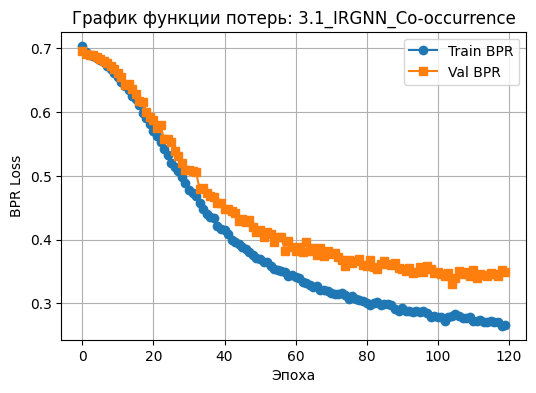

--- Обучение модели: 3.1_IRGNN_Cosine ---
epoch 0
 L Train: 0.6988
 L Val: 0.6924
epoch 1
 L Train: 0.6921
 L Val: 0.6902
epoch 2
 L Train: 0.6895
 L Val: 0.6877
epoch 3
 L Train: 0.6868
 L Val: 0.6851
epoch 4
 L Train: 0.6837
 L Val: 0.6834
epoch 5
 L Train: 0.6788
 L Val: 0.6795
epoch 6
 L Train: 0.6741
 L Val: 0.6719
epoch 7
 L Train: 0.6692
 L Val: 0.6665
epoch 8
 L Train: 0.6625
 L Val: 0.6607
epoch 9
 L Train: 0.6564
 L Val: 0.6572
epoch 10
 L Train: 0.6500
 L Val: 0.6518
epoch 11
 L Train: 0.6427
 L Val: 0.6480
epoch 12
 L Train: 0.6332
 L Val: 0.6387
epoch 13
 L Train: 0.6272
 L Val: 0.6339
epoch 14
 L Train: 0.6189
 L Val: 0.6263
epoch 15
 L Train: 0.6101
 L Val: 0.6168
epoch 16
 L Train: 0.6007
 L Val: 0.6102
epoch 17
 L Train: 0.5938
 L Val: 0.6045
epoch 18
 L Train: 0.5891
 L Val: 0.5912
epoch 19
 L Train: 0.5744
 L Val: 0.5827
epoch 20
 L Train: 0.5679
 L Val: 0.5811
epoch 21
 L Train: 0.5575
 L Val: 0.5730
epoch 22
 L Train: 0.5472
 L Val: 0.5576
epoch 23
 L Train: 0.5396

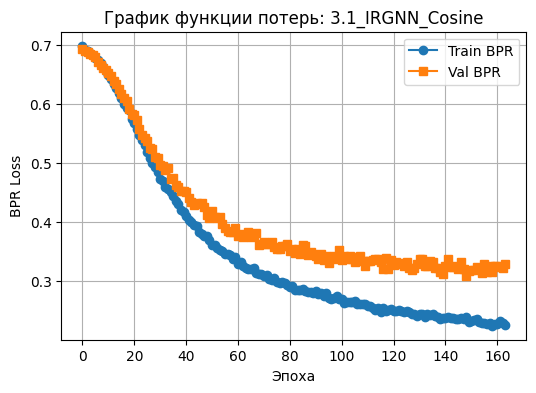

--- Обучение модели: 3.1_IRGNN_Jaccard ---
epoch 0
 L Train: 0.6974
 L Val: 0.6923
epoch 1
 L Train: 0.6925
 L Val: 0.6917
epoch 2
 L Train: 0.6901
 L Val: 0.6893
epoch 3
 L Train: 0.6882
 L Val: 0.6871
epoch 4
 L Train: 0.6849
 L Val: 0.6861
epoch 5
 L Train: 0.6819
 L Val: 0.6825
epoch 6
 L Train: 0.6780
 L Val: 0.6781
epoch 7
 L Train: 0.6733
 L Val: 0.6699
epoch 8
 L Train: 0.6682
 L Val: 0.6714
epoch 9
 L Train: 0.6623
 L Val: 0.6617
epoch 10
 L Train: 0.6571
 L Val: 0.6555
epoch 11
 L Train: 0.6481
 L Val: 0.6534
epoch 12
 L Train: 0.6448
 L Val: 0.6481
epoch 13
 L Train: 0.6337
 L Val: 0.6415
epoch 14
 L Train: 0.6248
 L Val: 0.6301
epoch 15
 L Train: 0.6164
 L Val: 0.6254
epoch 16
 L Train: 0.6103
 L Val: 0.6132
epoch 17
 L Train: 0.6034
 L Val: 0.6119
epoch 18
 L Train: 0.5934
 L Val: 0.6002
epoch 19
 L Train: 0.5791
 L Val: 0.5932
epoch 20
 L Train: 0.5713
 L Val: 0.5845
epoch 21
 L Train: 0.5612
 L Val: 0.5752
epoch 22
 L Train: 0.5500
 L Val: 0.5683
epoch 23
 L Train: 0.538

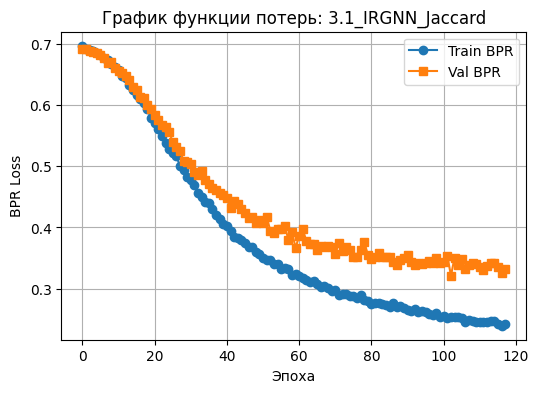

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
3.1_IRGNN_Co-occurrence,nan,nan,nan,0.880000,0.519201,0.229000,0.445287
3.1_IRGNN_Cosine,nan,nan,nan,0.905000,0.491299,0.226000,0.465357
3.1_IRGNN_Jaccard,nan,nan,nan,0.870000,0.509058,0.225500,0.443423


In [ ]:
tr_u = lfm_train_edges[0].numpy()
tr_i = lfm_train_edges[1].numpy()
ui_mat = csr_matrix((np.ones(len(tr_u)), (tr_u, tr_i)), shape=(u_count, i_count))
cooc = ui_mat.T.dot(ui_mat)

cooc_coo = cooc.tocoo()
coocc_ei = torch.tensor(np.vstack([cooc_coo.row, cooc_coo.col]), dtype=torch.long)
coocc_ew = torch.tensor(cooc_coo.data, dtype=torch.float32)

norms = np.sqrt(cooc.diagonal())

cosine_coo = cooc.tocoo().copy()
cosine_coo.data /= (norms[cosine_coo.row] * norms[cosine_coo.col] + 1e-9)
cosine_ei = torch.tensor(np.vstack([cosine_coo.row, cosine_coo.col]), dtype=torch.long)
cosine_ew = torch.tensor(cosine_coo.data, dtype=torch.float32)

union_mat = norms[cooc_coo.row]**2 + norms[cooc_coo.col]**2 - cooc_coo.data
jaccard_coo = cooc.tocoo().copy()
jaccard_coo.data /= (union_mat + 1e-9)
jaccard_ei = torch.tensor(np.vstack([jaccard_coo.row, jaccard_coo.col]), dtype=torch.long)
jaccard_ew = torch.tensor(jaccard_coo.data, dtype=torch.float32)

graphs_dict = {
    '3.1_IRGNN_Co-occurrence': (coocc_ei, coocc_ew),
    '3.1_IRGNN_Cosine': (cosine_ei, cosine_ew),
    '3.1_IRGNN_Jaccard': (jaccard_ei, jaccard_ew)
}

class IRGNN(torch.nn.Module):
    def __init__(self, num_u, num_i, dim):
        super().__init__()
        self.u_emb = torch.nn.Embedding(num_u, dim)
        self.i_emb = torch.nn.Embedding(num_i, dim)
        self.conv1 = GCNConv(dim, dim)
        self.conv2 = GCNConv(dim, dim)
    def get_embs(self, edge_index, edge_weight):
        i_x = self.conv2(F.relu(self.conv1(self.i_emb.weight, edge_index, edge_weight)), edge_index, edge_weight)
        return self.u_emb.weight, i_x

epochs_num = 200
patience = 15

for exp_name, (ei, ew) in graphs_dict.items():
    print(f"--- Обучение модели: {exp_name} ---")
    m_irgnn = IRGNN(u_count, i_count, 32)
    opt = torch.optim.Adam(m_irgnn.parameters(), lr=0.01)

    tr_losses = []
    vl_losses = []

    ew_norm = (ew - ew.min()) / (ew.max() - ew.min() + 1e-9)
    best_v_loss = float('inf')
    wait = 0
    best_weights = None

    for e in range(epochs_num):
        m_irgnn.train()
        opt.zero_grad()
        t_loss = bpr_loss_irgnn(m_irgnn, lfm_train_edges, ei, ew_norm, u_count, i_count)
        t_loss.backward()
        opt.step()

        m_irgnn.eval()
        with torch.no_grad():
            v_loss = bpr_loss_irgnn(m_irgnn, lfm_val_edges, ei, ew_norm, u_count, i_count)

        tr_losses.append(t_loss.item())
        vl_losses.append(v_loss.item())
        print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

        if v_loss.item() < best_v_loss:
            best_v_loss = v_loss.item()
            wait = 0
            best_weights = copy.deepcopy(m_irgnn.state_dict())
        else:
            wait += 1

        if wait >= patience:
            print(f'Early stopping на эпохе {e}')
            break

    if best_weights:
        m_irgnn.load_state_dict(best_weights)

    m_res = compute_irgnn_metrics(m_irgnn, ei, ew_norm, lfm_train_edges, lfm_val_edges, u_count, i_count)
    m_res['Experiment'] = exp_name
    part3_metrics_registry.append(m_res)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(range(len(tr_losses)), tr_losses, marker='o', label='Train BPR')
    ax.plot(range(len(vl_losses)), vl_losses, marker='s', label='Val BPR')
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('BPR Loss')
    ax.set_title(f'График функции потерь: {exp_name}')
    ax.legend()
    ax.grid(True)
    plt.show()

render_part3_dataframe(part3_metrics_registry)

## Задание 3.2: Работа с взвешенными рёбрами. Модификация IRGNN для передачи весов в сверточные слои.

--- Обучение модели: 3.2_IRGNN_Cosine_Unweighted ---
epoch 0
 L Train: 0.6931
 L Val: 0.6920
epoch 1
 L Train: 0.6915
 L Val: 0.6904
epoch 2
 L Train: 0.6900
 L Val: 0.6891
epoch 3
 L Train: 0.6874
 L Val: 0.6860
epoch 4
 L Train: 0.6847
 L Val: 0.6831
epoch 5
 L Train: 0.6822
 L Val: 0.6813
epoch 6
 L Train: 0.6757
 L Val: 0.6761
epoch 7
 L Train: 0.6721
 L Val: 0.6725
epoch 8
 L Train: 0.6665
 L Val: 0.6659
epoch 9
 L Train: 0.6619
 L Val: 0.6605
epoch 10
 L Train: 0.6565
 L Val: 0.6612
epoch 11
 L Train: 0.6506
 L Val: 0.6548
epoch 12
 L Train: 0.6430
 L Val: 0.6449
epoch 13
 L Train: 0.6376
 L Val: 0.6378
epoch 14
 L Train: 0.6304
 L Val: 0.6369
epoch 15
 L Train: 0.6229
 L Val: 0.6272
epoch 16
 L Train: 0.6173
 L Val: 0.6223
epoch 17
 L Train: 0.6064
 L Val: 0.6122
epoch 18
 L Train: 0.5985
 L Val: 0.6103
epoch 19
 L Train: 0.5917
 L Val: 0.5988
epoch 20
 L Train: 0.5849
 L Val: 0.5927
epoch 21
 L Train: 0.5751
 L Val: 0.5884
epoch 22
 L Train: 0.5652
 L Val: 0.5749
epoch 23
 L Tr

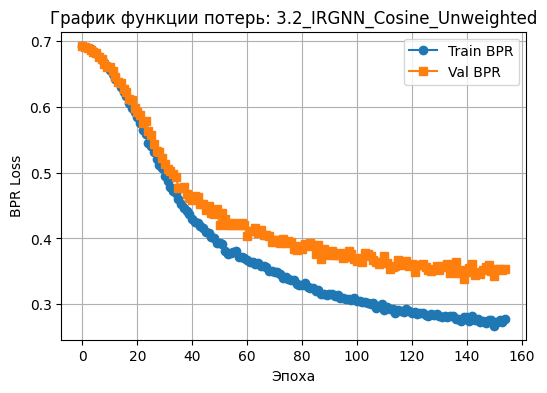

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
3.1_IRGNN_Co-occurrence,nan,nan,nan,0.880000,0.519201,0.229000,0.445287
3.1_IRGNN_Cosine,nan,nan,nan,0.905000,0.491299,0.226000,0.465357
3.1_IRGNN_Jaccard,nan,nan,nan,0.870000,0.509058,0.225500,0.443423
3.2_IRGNN_Cosine_Unweighted,nan,nan,nan,0.830000,0.472926,0.213000,0.391800


In [ ]:
exp_name_unweighted = '3.2_IRGNN_Cosine_Unweighted'
print(f"--- Обучение модели: {exp_name_unweighted} ---")

m_unw = IRGNN(u_count, i_count, 32)
opt_unw = torch.optim.Adam(m_unw.parameters(), lr=0.01)
epochs_num = 200
patience = 15

tr_losses = []
vl_losses = []
ei_cos = cosine_ei
ew_none = None

best_v_loss = float('inf')
wait = 0
best_weights = None

for e in range(epochs_num):
    m_unw.train()
    opt_unw.zero_grad()
    t_loss = bpr_loss_irgnn(m_unw, lfm_train_edges, ei_cos, ew_none, u_count, i_count)
    t_loss.backward()
    opt_unw.step()

    m_unw.eval()
    with torch.no_grad():
        v_loss = bpr_loss_irgnn(m_unw, lfm_val_edges, ei_cos, ew_none, u_count, i_count)

    tr_losses.append(t_loss.item())
    vl_losses.append(v_loss.item())
    print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

    if v_loss.item() < best_v_loss:
        best_v_loss = v_loss.item()
        wait = 0
        best_weights = copy.deepcopy(m_unw.state_dict())
    else:
        wait += 1

    if wait >= patience:
        print(f'Early stopping на эпохе {e}')
        break

if best_weights:
    m_unw.load_state_dict(best_weights)

m_res_unw = compute_irgnn_metrics(m_unw, ei_cos, ew_none, lfm_train_edges, lfm_val_edges, u_count, i_count)
m_res_unw['Experiment'] = exp_name_unweighted
part3_metrics_registry.append(m_res_unw)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(len(tr_losses)), tr_losses, marker='o', label='Train BPR')
ax.plot(range(len(vl_losses)), vl_losses, marker='s', label='Val BPR')
ax.set_xlabel('Эпоха')
ax.set_ylabel('BPR Loss')
ax.set_title(f'График функции потерь: {exp_name_unweighted}')
ax.legend()
ax.grid(True)
plt.show()

render_part3_dataframe(part3_metrics_registry)

## Задание 3.3: Гибридная модель. Ансамблирование предсказаний LightGCN и IRGNN по формуле: `final_score = α * score_LightGCN + (1-α) * score_IRGNN`.

In [ ]:
print(f"--- Обучение базовой модели LightGCN для ансамбля ---")

def bpr_loss_lgcn(model, edges, n_u, n_i):
    u_idx = edges[0]
    pos_i = edges[1]
    neg_i = torch.randint(n_u, n_u + n_i, (u_idx.size(0),), dtype=torch.long, device=edges.device)
    embs = model.get_embedding(edges)
    pos_sc = (embs[u_idx] * embs[pos_i]).sum(dim=1)
    neg_sc = (embs[u_idx] * embs[neg_i]).sum(dim=1)
    return model.recommendation_loss(pos_sc, neg_sc, node_id=torch.unique(torch.cat([u_idx, pos_i, neg_i])))

u_t_shift = lfm_train_edges[0]
i_t_shift = lfm_train_edges[1] + u_count
bipart_tr = torch.stack([u_t_shift, i_t_shift], dim=0)

lgcn = LightGCN(num_nodes=u_count + i_count, embedding_dim=32, num_layers=2)
opt_lgcn = torch.optim.Adam(lgcn.parameters(), lr=0.01)

epochs_num = 200
patience = 15
best_v_loss = float('inf')
wait = 0
best_weights = None

for e in range(epochs_num):
    lgcn.train()
    opt_lgcn.zero_grad()
    t_loss = bpr_loss_lgcn(lgcn, bipart_tr, u_count, i_count)
    t_loss.backward()
    opt_lgcn.step()

    lgcn.eval()
    with torch.no_grad():
        v_u = lfm_val_edges[0]
        v_i = lfm_val_edges[1] + u_count
        bipart_vl = torch.stack([v_u, v_i], dim=0)
        v_loss = bpr_loss_lgcn(lgcn, bipart_vl, u_count, i_count)

    print(f'epoch {e}\n L Train: {t_loss.item():.4f}\n L Val: {v_loss.item():.4f}')

    if v_loss.item() < best_v_loss:
        best_v_loss = v_loss.item()
        wait = 0
        best_weights = copy.deepcopy(lgcn.state_dict())
    else:
        wait += 1

    if wait >= patience:
        print(f'Early stopping на эпохе {e}')
        break

if best_weights:
    lgcn.load_state_dict(best_weights)

best_irgnn = m_irgnn
ew_cos_norm = (cosine_ew - cosine_ew.min()) / (cosine_ew.max() - cosine_ew.min() + 1e-9)

alphas = [0.2, 0.5, 0.8]
for alpha in alphas:
    exp_name_hyb = f'3.3_Hybrid_Ensemble_Alpha_{alpha}'
    print(f"--- Оценка ансамбля: {exp_name_hyb} ---")

    lgcn.eval()
    best_irgnn.eval()

    with torch.no_grad():
        embs_lgcn = lgcn.get_embedding(bipart_tr).cpu().numpy()
        emb_u_i, emb_i_i = best_irgnn.get_embs(cosine_ei, ew_cos_norm)
        emb_u_i = emb_u_i.cpu().numpy()
        emb_i_i = emb_i_i.cpu().numpy()

        test_u = lfm_val_edges[0].cpu().numpy()
        test_i = lfm_val_edges[1].cpu().numpy()
        df_eval = pd.DataFrame({'u': test_u, 'i': test_i})

        hits = []; mrrs = []; precs = []; recs = []
        eval_users = df_eval['u'].unique()
        eval_users = np.random.choice(eval_users, min(200, len(eval_users)), replace=False)

        for u in eval_users:
            pos_items = df_eval[df_eval['u'] == u]['i'].values
            if len(pos_items) == 0: continue

            neg_items = np.random.randint(0, i_count, 100)
            test_items = np.concatenate([pos_items, neg_items])

            sc_l = np.dot(embs_lgcn[test_items + u_count], embs_lgcn[u])
            sc_i = np.dot(emb_i_i[test_items], emb_u_i[u])

            min_l, max_l = sc_l.min(), sc_l.max()
            norm_l = (sc_l - min_l) / (max_l - min_l + 1e-9)
            min_i, max_i = sc_i.min(), sc_i.max()
            norm_i = (sc_i - min_i) / (max_i - min_i + 1e-9)

            hyb_sc = alpha * norm_l + (1 - alpha) * norm_i

            labels = np.concatenate([np.ones(len(pos_items)), np.zeros(len(neg_items))])
            sort_idx = np.argsort(hyb_sc)[::-1]
            sorted_labels = labels[sort_idx]
            top10 = sorted_labels[:10]

            hits.append(1 if np.sum(top10) > 0 else 0)
            first_pos = np.where(sorted_labels == 1)[0]
            mrrs.append(1.0 / (first_pos[0] + 1) if len(first_pos) > 0 else 0.0)
            precs.append(np.sum(top10) / 10.0)
            recs.append(np.sum(top10) / len(pos_items))

    m_res_hyb = {'MSE': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Hits@10': np.mean(hits), 'MRR': np.mean(mrrs), 'Precision@10': np.mean(precs), 'Recall@10': np.mean(recs)}
    m_res_hyb['Experiment'] = exp_name_hyb
    part3_metrics_registry.append(m_res_hyb)

print("ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА ЧАСТИ 3:")
render_part3_dataframe(part3_metrics_registry)

--- Обучение базовой модели LightGCN для ансамбля ---
epoch 0
 L Train: 0.6931
 L Val: 0.6932
epoch 1
 L Train: 0.6931
 L Val: 0.6931
epoch 2
 L Train: 0.6930
 L Val: 0.6931
epoch 3
 L Train: 0.6928
 L Val: 0.6930
epoch 4
 L Train: 0.6926
 L Val: 0.6928
epoch 5
 L Train: 0.6923
 L Val: 0.6926
epoch 6
 L Train: 0.6918
 L Val: 0.6922
epoch 7
 L Train: 0.6913
 L Val: 0.6918
epoch 8
 L Train: 0.6907
 L Val: 0.6913
epoch 9
 L Train: 0.6899
 L Val: 0.6905
epoch 10
 L Train: 0.6889
 L Val: 0.6896
epoch 11
 L Train: 0.6878
 L Val: 0.6886
epoch 12
 L Train: 0.6866
 L Val: 0.6874
epoch 13
 L Train: 0.6851
 L Val: 0.6861
epoch 14
 L Train: 0.6834
 L Val: 0.6846
epoch 15
 L Train: 0.6816
 L Val: 0.6828
epoch 16
 L Train: 0.6795
 L Val: 0.6807
epoch 17
 L Train: 0.6770
 L Val: 0.6786
epoch 18
 L Train: 0.6746
 L Val: 0.6765
epoch 19
 L Train: 0.6719
 L Val: 0.6738
epoch 20
 L Train: 0.6687
 L Val: 0.6712
epoch 21
 L Train: 0.6655
 L Val: 0.6681
epoch 22
 L Train: 0.6620
 L Val: 0.6642
epoch 23
 L T

,MSE,RMSE,MAE,Hits@10,MRR,Precision@10,Recall@10
Experiment,,,,,,,
3.1_IRGNN_Co-occurrence,nan,nan,nan,0.880000,0.519201,0.229000,0.445287
3.1_IRGNN_Cosine,nan,nan,nan,0.905000,0.491299,0.226000,0.465357
3.1_IRGNN_Jaccard,nan,nan,nan,0.870000,0.509058,0.225500,0.443423
3.2_IRGNN_Cosine_Unweighted,nan,nan,nan,0.830000,0.472926,0.213000,0.391800
3.3_Hybrid_Ensemble_Alpha_0.2,nan,nan,nan,0.880000,0.506350,0.230500,0.462230
3.3_Hybrid_Ensemble_Alpha_0.5,nan,nan,nan,0.875000,0.523464,0.226000,0.461833
3.3_Hybrid_Ensemble_Alpha_0.8,nan,nan,nan,0.855000,0.477642,0.231500,0.454640
